# MovieLens Recommendation System with Collaborative Filtering

Author: Violetta Kalinicheva  
Original analysis: August 2026; portfolio validation: October 28, 2026

## Decision and evaluation boundary

Can item-to-item collaborative filtering retrieve a later liked title more reliably than popularity, when the input is one liked movie? The audience is a recommendation-product team evaluating an offline discovery prototype. This is a **transductive retrospective benchmark**, not a production service or a prospective global-time backtest. Ratings of at least four stars define positive preference; missing ratings are unknown, not dislikes.

Reproduce with `python run.py` after setting `PROJECT_DATA_DIR` to the extracted official MovieLens 32M directory. Raw ratings stay outside the repository.

In [1]:
# I am limiting numerical workers so this full-data run remains resource-aware.
import os

for thread_variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[thread_variable] = "4"
import time
import json
import hashlib
import platform
import importlib.metadata
from pathlib import Path
from threadpoolctl import threadpool_limits

threadpool_limits(limits=4)
get_ipython().run_line_magic("matplotlib", "inline")
run_started = time.monotonic()


def sha256_file(path):
    result = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


source_notebook_sha256 = "7d1d82ffdbcae9eff9305be989ba0e6d35dea46e52446e9a491559609b55149c"


## Introduction

The goal of this project is to create a recommender system that allows a user to enter a movie they like and receive ten other movie recommendations. The analysis uses the MovieLens 32M benchmark dataset, which contains movie ratings, user-generated tags, movie titles and genres, and external movie identifiers.

Although the assignment describes the MovieLens data as “small,” the provided files are the MovieLens 32M benchmark. Therefore, I will use a memory-conscious workflow that preserves the complete source data while avoiding unnecessary loading or copying of the 836 MB ratings file.

The central analytical question is:

**Can the rating behavior of MovieLens users identify ten movies that are meaningfully similar to a movie selected by the user?**

The final system will use validated movie and rating information, establish a simple recommendation baseline, build an item-to-item collaborative-filtering model, evaluate its recommendation quality, and provide a reusable recommendation function.

In [2]:
# I am verifying this analytical stage before interpreting its evidence.
from pathlib import Path
import hashlib
import platform
import sys
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
data_folder = Path(os.environ.get("PROJECT_DATA_DIR", "data")).expanduser()
required_files = {
    "Movies": data_folder / "movies.csv",
    "Ratings": data_folder / "ratings.csv",
    "Tags": data_folder / "tags.csv",
    "Links": data_folder / "links.csv",
    "README": data_folder / "README.txt",
    "Checksums": data_folder / "checksums.txt",
}
missing_files = [str(file_path) for file_path in required_files.values() if not file_path.exists()]
if missing_files:
    raise FileNotFoundError(
        "The following required MovieLens files are missing:\n" + "\n".join(missing_files)
    )
expected_checksums = {}
with required_files["Checksums"].open("r", encoding="utf-8") as checksum_file:
    for checksum_line in checksum_file:
        checksum_parts = checksum_line.strip().split()
        if len(checksum_parts) == 2:
            expected_checksum, file_name = checksum_parts
            expected_checksums[file_name] = expected_checksum


def calculate_md5(file_path, block_size=8 * 1024 * 1024):
    md5_hash = hashlib.md5()
    with file_path.open("rb") as source_file:
        while True:
            data_block = source_file.read(block_size)
            if not data_block:
                break
            md5_hash.update(data_block)
    return md5_hash.hexdigest()


def count_csv_rows(file_path, block_size=8 * 1024 * 1024):
    total_lines = 0
    final_byte = b""
    with file_path.open("rb") as source_file:
        while True:
            data_block = source_file.read(block_size)
            if not data_block:
                break
            total_lines += data_block.count(b"\n")
            final_byte = data_block[-1:]
    if final_byte and final_byte != b"\n":
        total_lines += 1
    return total_lines - 1


documented_row_counts = {
    "movies.csv": 87585,
    "ratings.csv": 32000204,
    "tags.csv": 2000072,
    "links.csv": 87585,
}
inventory_records = []
for dataset_name in ["Movies", "Ratings", "Tags", "Links"]:
    file_path = required_files[dataset_name]
    file_name = file_path.name
    observed_checksum = calculate_md5(file_path)
    expected_checksum = expected_checksums.get(file_name)
    observed_rows = count_csv_rows(file_path)
    expected_rows = documented_row_counts[file_name]
    inventory_records.append(
        {
            "Dataset": dataset_name,
            "File": file_name,
            "File Size (MB)": file_path.stat().st_size / 1024**2,
            "Observed Rows": observed_rows,
            "Documented Rows": expected_rows,
            "Row Count Matches": observed_rows == expected_rows,
            "Checksum Matches": observed_checksum == expected_checksum,
        }
    )
file_inventory = pd.DataFrame(inventory_records)
assert file_inventory[
    "Row Count Matches"
].all(), "At least one CSV row count does not match the README."
assert file_inventory[
    "Checksum Matches"
].all(), "At least one source file failed checksum validation."
movies_sample = pd.read_csv(
    required_files["Movies"],
    nrows=3,
    encoding="utf-8",
    dtype={"movieId": "int32", "title": "string", "genres": "string"},
)
ratings_sample = pd.read_csv(
    required_files["Ratings"],
    nrows=3,
    encoding="utf-8",
    dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},
)
tags_sample = pd.read_csv(
    required_files["Tags"],
    nrows=3,
    encoding="utf-8",
    dtype={"userId": "int32", "movieId": "int32", "tag": "string", "timestamp": "int64"},
)
links_sample = pd.read_csv(
    required_files["Links"],
    nrows=3,
    encoding="utf-8",
    dtype={"movieId": "int32", "imdbId": "string", "tmdbId": "Int64"},
)
dataset_samples = {
    "Movies": movies_sample,
    "Ratings": ratings_sample,
    "Tags": tags_sample,
    "Links": links_sample,
}
field_descriptions = {
    ("Movies", "movieId"): "Anonymous MovieLens movie identifier",
    ("Movies", "title"): "Movie title, usually including release year",
    ("Movies", "genres"): "Pipe-separated list of assigned genres",
    ("Ratings", "userId"): "Anonymous MovieLens user identifier",
    ("Ratings", "movieId"): "MovieLens movie identifier",
    ("Ratings", "rating"): "User rating from 0.5 to 5.0 stars",
    ("Ratings", "timestamp"): "Rating time in UTC Unix seconds",
    ("Tags", "userId"): "Anonymous MovieLens user identifier",
    ("Tags", "movieId"): "MovieLens movie identifier",
    ("Tags", "tag"): "User-generated word or short phrase",
    ("Tags", "timestamp"): "Tag-application time in UTC Unix seconds",
    ("Links", "movieId"): "MovieLens movie identifier",
    ("Links", "imdbId"): "IMDb movie identifier",
    ("Links", "tmdbId"): "The Movie Database identifier",
}
schema_records = []
for dataset_name, sample_data in dataset_samples.items():
    for column_name in sample_data.columns:
        schema_records.append(
            {
                "Dataset": dataset_name,
                "Column": column_name,
                "Data Type": str(sample_data[column_name].dtype),
                "Meaning": field_descriptions.get((dataset_name, column_name), "Requires review"),
            }
        )
schema_summary = pd.DataFrame(schema_records)
analytical_contract = pd.DataFrame(
    {
        "Analytical Element": [
            "Business question",
            "User input",
            "System output",
            "Primary unit in ratings data",
            "Primary outcome",
            "Target population",
            "Dataset time boundary",
            "Planned model family",
            "Important limitation",
        ],
        "Definition": [
            "Which ten movies should be recommended after a user selects one movie they like?",
            "One valid MovieLens movie title",
            "Ten other recommended MovieLens titles",
            "One rating by one anonymous user for one movie",
            "Ranked relevance of candidate movies",
            "MovieLens users represented in the supplied research dataset",
            "January 9, 1995 through October 12, 2023",
            "Item-to-item collaborative filtering",
            "Recommendations reflect historical MovieLens behavior and are not personalized beyond the selected movie",
        ],
    }
)
print("Data directory configured; paths are not included in published output.")
print(f"Python Version: {platform.python_version()}")
print("Python environment:", platform.python_version())
print("\nMovieLens Source File Verification:")
display(file_inventory)
print("\nAnalytical Contract:")
display(analytical_contract)
print("\nInitial Schema Summary:")
display(schema_summary)
for dataset_name, sample_data in dataset_samples.items():
    print("Schema inspection complete; raw record previews are not published.")
print("\nSection 1 source verification completed successfully.")


Data directory configured; paths are not included in published output.
Python Version: 3.12.14
Python environment: 3.12.14

MovieLens Source File Verification:


,Dataset,File,File Size (MB),Observed Rows,Documented Rows,Row Count Matches,Checksum Matches
0,Movies,movies.csv,4.046,87585,87585,True,True
1,Ratings,ratings.csv,836.445,32000204,32000204,True,True
2,Tags,tags.csv,69.002,2000072,2000072,True,True
3,Links,links.csv,1.860,87585,87585,True,True



Analytical Contract:


,Analytical Element,Definition
0,Business question,Which ten movies should be recommended after a user selects one movie they l...
1,User input,One valid MovieLens movie title
2,System output,Ten other recommended MovieLens titles
3,Primary unit in ratings data,One rating by one anonymous user for one movie
4,Primary outcome,Ranked relevance of candidate movies
5,Target population,MovieLens users represented in the supplied research dataset
6,Dataset time boundary,"January 9, 1995 through October 12, 2023"
7,Planned model family,Item-to-item collaborative filtering
8,Important limitation,Recommendations reflect historical MovieLens behavior and are not personaliz...



Initial Schema Summary:


,Dataset,Column,Data Type,Meaning
0,Movies,movieId,int32,Anonymous MovieLens movie identifier
1,Movies,title,string,"Movie title, usually including release year"
2,Movies,genres,string,Pipe-separated list of assigned genres
3,Ratings,userId,int32,Anonymous MovieLens user identifier
4,Ratings,movieId,int32,MovieLens movie identifier
5,Ratings,rating,float32,User rating from 0.5 to 5.0 stars
6,Ratings,timestamp,int64,Rating time in UTC Unix seconds
7,Tags,userId,int32,Anonymous MovieLens user identifier
8,Tags,movieId,int32,MovieLens movie identifier
9,Tags,tag,string,User-generated word or short phrase


Schema inspection complete; raw record previews are not published.
Schema inspection complete; raw record previews are not published.
Schema inspection complete; raw record previews are not published.
Schema inspection complete; raw record previews are not published.

Section 1 source verification completed successfully.


### Section 1 Interpretation
The source verification confirms that this is the complete and authentic MovieLens 32M dataset. All four files match the official checksums and documented row counts, including 32,000,204 ratings across 87,585 cataloged movies. Each ratings record represents one anonymous user’s rating of one movie, making item-to-item collaborative filtering appropriate for this prototype. Because the ratings file is approximately 836 MB, the remaining analysis will scan it in memory-safe chunks. This changes only how the data is processed, not which observations are included.

## Section 2: Data-Quality and Rating-Coverage Audit

Before cleaning or modeling, I audited the complete dataset for missing values, duplicates, invalid ratings, identifier problems, chronological coverage, and uneven user or movie activity. Because the ratings file contains more than 32 million records, I processed it in chunks while still examining every observation. This section determines which issues require correction and which represent valid characteristics of the MovieLens data.

In [3]:
# I am verifying this analytical stage before interpreting its evidence.
from pathlib import Path
import gc
import numpy as np
import pandas as pd
from IPython.display import display

data_folder = Path(os.environ.get("PROJECT_DATA_DIR", "data")).expanduser()
movies_path = data_folder / "movies.csv"
ratings_path = data_folder / "ratings.csv"
tags_path = data_folder / "tags.csv"
links_path = data_folder / "links.csv"
required_paths = [movies_path, ratings_path, tags_path, links_path]
if not all((path.exists() for path in required_paths)):
    missing_files = [path.name for path in required_paths if not path.exists()]
    raise FileNotFoundError(f"The following required files were not found: {missing_files}")
movies_raw = pd.read_csv(
    movies_path, dtype={"movieId": "int32", "title": "string", "genres": "string"}
)
links_raw = pd.read_csv(
    links_path, dtype={"movieId": "int32", "imdbId": "string", "tmdbId": "Int64"}
)
tags_raw = pd.read_csv(
    tags_path, dtype={"userId": "int32", "movieId": "int32", "tag": "string", "timestamp": "int64"}
)
initial_movie_array_length = int(movies_raw["movieId"].max()) + 1
movie_rating_counts = np.zeros(initial_movie_array_length, dtype=np.int64)
movie_rating_sums = np.zeros(initial_movie_array_length, dtype=np.float64)
user_rating_counts = np.zeros(1, dtype=np.int64)
rating_frequency = np.zeros(11, dtype=np.int64)
ratings_columns = ["userId", "movieId", "rating", "timestamp"]
ratings_missing_totals = pd.Series(0, index=ratings_columns, dtype="int64")
ratings_total_rows = 0
duplicate_rating_pairs = 0
rating_sort_violations = 0
invalid_rating_increments = 0
invalid_rating_range = 0
rating_sum = 0.0
rating_sum_squared = 0.0
minimum_rating = np.inf
maximum_rating = -np.inf
minimum_timestamp = None
maximum_timestamp = None
previous_rating_key = None
rating_key_base = 1000000
ratings_chunk_size = 1000000
for rating_chunk in pd.read_csv(
    ratings_path,
    usecols=ratings_columns,
    dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},
    chunksize=ratings_chunk_size,
):
    ratings_total_rows += len(rating_chunk)
    ratings_missing_totals += rating_chunk.isna().sum()
    user_ids = rating_chunk["userId"].to_numpy(dtype=np.int64)
    movie_ids = rating_chunk["movieId"].to_numpy(dtype=np.int64)
    rating_values = rating_chunk["rating"].to_numpy(dtype=np.float64)
    timestamps = rating_chunk["timestamp"].to_numpy(dtype=np.int64)
    largest_user_id = int(user_ids.max())
    if largest_user_id >= len(user_rating_counts):
        user_rating_counts = np.pad(
            user_rating_counts, (0, largest_user_id - len(user_rating_counts) + 1)
        )
    user_rating_counts += np.bincount(user_ids, minlength=len(user_rating_counts))[
        : len(user_rating_counts)
    ]
    largest_movie_id = int(movie_ids.max())
    if largest_movie_id >= len(movie_rating_counts):
        extra_positions = largest_movie_id - len(movie_rating_counts) + 1
        movie_rating_counts = np.pad(movie_rating_counts, (0, extra_positions))
        movie_rating_sums = np.pad(movie_rating_sums, (0, extra_positions))
    movie_rating_counts += np.bincount(movie_ids, minlength=len(movie_rating_counts))[
        : len(movie_rating_counts)
    ]
    movie_rating_sums += np.bincount(
        movie_ids, weights=rating_values, minlength=len(movie_rating_sums)
    )[: len(movie_rating_sums)]
    doubled_ratings = rating_values * 2
    rounded_rating_steps = np.rint(doubled_ratings).astype(np.int8)
    invalid_rating_increments += int(
        np.count_nonzero(~np.isclose(doubled_ratings, rounded_rating_steps))
    )
    invalid_rating_range += int(np.count_nonzero((rating_values < 0.5) | (rating_values > 5.0)))
    rating_frequency += np.bincount(rounded_rating_steps, minlength=11)[:11]
    rating_keys = user_ids * rating_key_base + movie_ids
    within_chunk_differences = np.diff(rating_keys)
    duplicate_rating_pairs += int(np.count_nonzero(within_chunk_differences == 0))
    rating_sort_violations += int(np.count_nonzero(within_chunk_differences < 0))
    if previous_rating_key is not None:
        duplicate_rating_pairs += int(rating_keys[0] == previous_rating_key)
        rating_sort_violations += int(rating_keys[0] < previous_rating_key)
    previous_rating_key = int(rating_keys[-1])
    rating_sum += float(rating_values.sum())
    rating_sum_squared += float(np.square(rating_values).sum())
    minimum_rating = min(minimum_rating, float(rating_values.min()))
    maximum_rating = max(maximum_rating, float(rating_values.max()))
    chunk_minimum_timestamp = int(timestamps.min())
    chunk_maximum_timestamp = int(timestamps.max())
    minimum_timestamp = (
        chunk_minimum_timestamp
        if minimum_timestamp is None
        else min(minimum_timestamp, chunk_minimum_timestamp)
    )
    maximum_timestamp = (
        chunk_maximum_timestamp
        if maximum_timestamp is None
        else max(maximum_timestamp, chunk_maximum_timestamp)
    )
global_mean_rating = rating_sum / ratings_total_rows
global_rating_variance = rating_sum_squared / ratings_total_rows - global_mean_rating**2
global_rating_standard_deviation = np.sqrt(max(global_rating_variance, 0))
rating_start_date = pd.to_datetime(minimum_timestamp, unit="s", utc=True)
rating_end_date = pd.to_datetime(maximum_timestamp, unit="s", utc=True)
ratings_per_active_user = user_rating_counts[user_rating_counts > 0]
rated_movie_ids = np.flatnonzero(movie_rating_counts > 0)
catalog_movie_ids = movies_raw["movieId"].to_numpy(dtype=np.int64)
rating_movie_ids_without_catalog = np.setdiff1d(rated_movie_ids, catalog_movie_ids)
catalog_movie_ids_without_ratings = np.setdiff1d(catalog_movie_ids, rated_movie_ids)
catalog_rating_counts = movie_rating_counts[catalog_movie_ids]
catalog_rating_sums = movie_rating_sums[catalog_movie_ids]
catalog_mean_ratings = np.divide(
    catalog_rating_sums,
    catalog_rating_counts,
    out=np.full(len(catalog_movie_ids), np.nan, dtype=np.float64),
    where=catalog_rating_counts > 0,
)
movie_rating_summary = movies_raw.copy()
movie_rating_summary["rating_count"] = catalog_rating_counts
movie_rating_summary["mean_rating"] = catalog_mean_ratings
blank_tag_count = int(tags_raw["tag"].fillna("").str.strip().eq("").sum())
tags_exact_duplicates = int(tags_raw.duplicated().sum())
movies_exact_duplicates = int(movies_raw.duplicated().sum())
links_exact_duplicates = int(links_raw.duplicated().sum())
duplicate_movie_id_count = int(movies_raw["movieId"].duplicated().sum())
duplicate_link_movie_id_count = int(links_raw["movieId"].duplicated().sum())
duplicate_title_mask = movies_raw["title"].duplicated(keep=False)
duplicate_title_rows = int(duplicate_title_mask.sum())
duplicate_title_groups = int(
    movies_raw.loc[duplicate_title_mask, "title"].value_counts().gt(1).sum()
)
movies_without_genres = int(movies_raw["genres"].eq("(no genres listed)").sum())
title_has_trailing_year = movies_raw["title"].str.contains("\\(\\d{4}\\)$", regex=True, na=False)
titles_without_trailing_year = int((~title_has_trailing_year).sum())
dataset_quality_summary = pd.DataFrame(
    {
        "Dataset": ["Movies", "Ratings", "Tags", "Links"],
        "Rows": [len(movies_raw), ratings_total_rows, len(tags_raw), len(links_raw)],
        "Missing Cells": [
            int(movies_raw.isna().sum().sum()),
            int(ratings_missing_totals.sum()),
            int(tags_raw.isna().sum().sum()),
            int(links_raw.isna().sum().sum()),
        ],
        "Exact Duplicate Rows": [
            movies_exact_duplicates,
            duplicate_rating_pairs,
            tags_exact_duplicates,
            links_exact_duplicates,
        ],
        "Unique Users": [
            "Not Applicable",
            f"{len(ratings_per_active_user):,}",
            f"{tags_raw['userId'].nunique():,}",
            "Not Applicable",
        ],
        "Unique Movies": [
            f"{movies_raw['movieId'].nunique():,}",
            f"{len(rated_movie_ids):,}",
            f"{tags_raw['movieId'].nunique():,}",
            f"{links_raw['movieId'].nunique():,}",
        ],
    }
)
ratings_audit_summary = pd.DataFrame(
    {
        "Ratings Audit Check": [
            "Complete rating observations",
            "Unique rating users",
            "Movies receiving at least one rating",
            "Missing rating cells",
            "Repeated user-movie rating pairs",
            "User-movie sort-order violations",
            "Ratings outside 0.5–5.0",
            "Ratings not in half-star increments",
            "Minimum ratings by an active user",
            "Maximum ratings by an active user",
            "Global mean rating",
            "Global rating standard deviation",
            "First rating timestamp",
            "Last rating timestamp",
        ],
        "Result": [
            f"{ratings_total_rows:,}",
            f"{len(ratings_per_active_user):,}",
            f"{len(rated_movie_ids):,}",
            f"{int(ratings_missing_totals.sum()):,}",
            f"{duplicate_rating_pairs:,}",
            f"{rating_sort_violations:,}",
            f"{invalid_rating_range:,}",
            f"{invalid_rating_increments:,}",
            f"{ratings_per_active_user.min():,}",
            f"{ratings_per_active_user.max():,}",
            f"{global_mean_rating:.3f}",
            f"{global_rating_standard_deviation:.3f}",
            rating_start_date.strftime("%B %d, %Y %H:%M:%S UTC"),
            rating_end_date.strftime("%B %d, %Y %H:%M:%S UTC"),
        ],
    }
)
rating_distribution = pd.DataFrame(
    {"Rating": np.arange(0.5, 5.1, 0.5), "Rating_Count": rating_frequency[1:11]}
)
rating_distribution["Percentage"] = rating_distribution["Rating_Count"] / ratings_total_rows * 100
rating_distribution["Rating_Count"] = rating_distribution["Rating_Count"].map(
    lambda value: f"{value:,}"
)
rating_distribution["Percentage"] = rating_distribution["Percentage"].map(
    lambda value: f"{value:.2f}%"
)
user_activity_summary = pd.DataFrame(
    {
        "User Activity Measure": [
            "Minimum ratings per active user",
            "25th percentile",
            "Median ratings per active user",
            "75th percentile",
            "90th percentile",
            "99th percentile",
            "Maximum ratings per active user",
        ],
        "Ratings": [
            int(ratings_per_active_user.min()),
            int(np.percentile(ratings_per_active_user, 25)),
            int(np.median(ratings_per_active_user)),
            int(np.percentile(ratings_per_active_user, 75)),
            int(np.percentile(ratings_per_active_user, 90)),
            int(np.percentile(ratings_per_active_user, 99)),
            int(ratings_per_active_user.max()),
        ],
    }
)
catalog_quality_summary = pd.DataFrame(
    {
        "Catalog or Link Check": [
            "Duplicate movie identifiers",
            "Duplicate link-table movie identifiers",
            "Rows participating in duplicated exact titles",
            "Duplicated exact-title groups",
            "Movies with no listed genres",
            "Titles without a trailing four-digit year",
            "Rated movie identifiers absent from the catalog",
            "Catalog movies without any ratings",
            "Missing TMDB identifiers",
            "Missing or blank tag values",
        ],
        "Result": [
            duplicate_movie_id_count,
            duplicate_link_movie_id_count,
            duplicate_title_rows,
            duplicate_title_groups,
            movies_without_genres,
            titles_without_trailing_year,
            len(rating_movie_ids_without_catalog),
            len(catalog_movie_ids_without_ratings),
            int(links_raw["tmdbId"].isna().sum()),
            blank_tag_count,
        ],
    }
)
assert ratings_total_rows == 32000204
assert int(ratings_missing_totals.sum()) == 0
assert duplicate_rating_pairs == 0
assert rating_sort_violations == 0
assert invalid_rating_range == 0
assert invalid_rating_increments == 0
assert ratings_per_active_user.min() >= 20
assert len(rating_movie_ids_without_catalog) == 0
assert movie_rating_summary["rating_count"].sum() == ratings_total_rows
assert int(title_has_trailing_year.sum()) + titles_without_trailing_year == len(movies_raw)
assert 0 <= titles_without_trailing_year <= len(movies_raw)
print("Dataset Quality Summary:")
display(dataset_quality_summary)
print("\nComplete Ratings Audit:")
display(ratings_audit_summary)
print("\nRating Distribution:")
display(rating_distribution)
print("\nUser Activity Distribution:")
display(user_activity_summary)
print("\nCatalog, Tag, and Link Review:")
display(catalog_quality_summary)
del tags_raw
gc.collect()
print("\nSection 2 data-quality audit completed successfully using every rating observation.")


Dataset Quality Summary:


,Dataset,Rows,Missing Cells,Exact Duplicate Rows,Unique Users,Unique Movies
0,Movies,87585,0,0,Not Applicable,"87,585"
1,Ratings,32000204,0,0,"200,948","84,432"
2,Tags,2000072,17,0,"15,848","51,323"
3,Links,87585,124,0,Not Applicable,"87,585"



Complete Ratings Audit:


,Ratings Audit Check,Result
0,Complete rating observations,"32,000,204"
1,Unique rating users,"200,948"
2,Movies receiving at least one rating,"84,432"
3,Missing rating cells,0
4,Repeated user-movie rating pairs,0
5,User-movie sort-order violations,0
6,Ratings outside 0.5–5.0,0
7,Ratings not in half-star increments,0
8,Minimum ratings by an active user,20
9,Maximum ratings by an active user,"33,332"



Rating Distribution:


...


User Activity Distribution:


,User Activity Measure,Ratings
0,Minimum ratings per active user,20
1,25th percentile,36
2,Median ratings per active user,73
3,75th percentile,167
4,90th percentile,364
5,99th percentile,1290
6,Maximum ratings per active user,33332



Catalog, Tag, and Link Review:


,Catalog or Link Check,Result
0,Duplicate movie identifiers,0
1,Duplicate link-table movie identifiers,0
2,Rows participating in duplicated exact titles,401
3,Duplicated exact-title groups,198
4,Movies with no listed genres,7080
5,Titles without a trailing four-digit year,771
6,Rated movie identifiers absent from the catalog,0
7,Catalog movies without any ratings,3153
8,Missing TMDB identifiers,124
9,Missing or blank tag values,23



Section 2 data-quality audit completed successfully using every rating observation.


### Section 2 Interpretation
The audit confirms that the core recommendation data is exceptionally clean. All 32,000,204 ratings from 200,948 users were examined, with no missing values, repeated user–movie pairs, invalid scores, or unmatched movie identifiers. Ratings average 3.54 stars with a standard deviation of 1.06, and 49.8% of all ratings are 4.0 stars or higher. This gives us a defensible definition of a “liked” movie for the recommendation model.

User activity is highly uneven: the median user provided 73 ratings, while the most active user provided 33,332. This means very active users could have disproportionate influence unless the model uses normalized similarity and minimum-support safeguards. The catalog also includes 3,153 movies without ratings, 7,080 without listed genres, and 771 without a standard release year. These are valid limitations rather than data errors, so I will preserve them. Repeated titles will be distinguished by their unique MovieLens identifiers. Overall, the ratings data is ready for modeling, but the system must handle sparse movies and unequal user activity carefully.

## Section 3: Data Preparation and Evaluation Design

I preserved the original source data and created only the fields required for reliable movie matching and collaborative filtering. A rating of 4.0 or higher is treated as evidence that a user liked a movie because the assignment begins with a movie the user already likes. Lower ratings remain valid source observations but are not treated as positive preferences.

To evaluate the recommender without using the same interaction for training and testing, I selected a reproducible sample of users and reserved each eligible user’s most recently recorded positive interaction as a held-out target. The preceding positive interaction becomes the single seed movie. This makes the evaluation closely match the final task: beginning with one liked movie and attempting to recover another movie the user also liked.

In [4]:
# I am verifying this analytical stage before interpreting its evidence.
positive_rating_threshold = 4.0
random_seed = 530
requested_evaluation_users = 20000
ratings_chunk_size = 1000000
random_generator = np.random.default_rng(random_seed)
movies_clean = movie_rating_summary.copy()
movies_clean["display_title"] = movies_clean["title"].str.strip()
raw_title_text = movies_clean["title"]
clean_title_text = movies_clean["display_title"]
title_whitespace_changed_count = int(raw_title_text.ne(clean_title_text).sum())
raw_title_has_trailing_year = raw_title_text.str.contains("\\(\\d{4}\\)$", regex=True, na=False)
clean_title_has_trailing_year = clean_title_text.str.contains("\\(\\d{4}\\)$", regex=True, na=False)
raw_titles_without_year = int((~raw_title_has_trailing_year).sum())
clean_titles_without_year = int((~clean_title_has_trailing_year).sum())
release_years_recovered_by_trimming = int(
    (~raw_title_has_trailing_year & clean_title_has_trailing_year).sum()
)
movies_clean["release_year"] = pd.to_numeric(
    movies_clean["display_title"].str.extract("\\((\\d{4})\\)$", expand=False), errors="coerce"
).astype("Int16")
movies_clean["title_without_year"] = (
    movies_clean["display_title"].str.replace("\\s*\\(\\d{4}\\)$", "", regex=True).str.strip()
)
movies_clean["normalized_title"] = (
    movies_clean["title_without_year"]
    .str.casefold()
    .str.replace("\\s+", " ", regex=True)
    .str.strip()
)
movies_clean["display_key"] = (
    movies_clean["display_title"]
    + " [MovieLens ID "
    + movies_clean["movieId"].astype("string")
    + "]"
)
movies_clean["has_listed_genres"] = movies_clean["genres"].ne("(no genres listed)")
movies_clean["genre_count"] = np.where(
    movies_clean["has_listed_genres"], movies_clean["genres"].str.count("\\|").add(1), 0
).astype("int16")
movies_clean["has_rating_history"] = movies_clean["rating_count"] > 0
active_user_ids = np.flatnonzero(user_rating_counts > 0)
evaluation_sample_size = min(requested_evaluation_users, len(active_user_ids))
evaluation_user_ids = np.sort(
    random_generator.choice(active_user_ids, size=evaluation_sample_size, replace=False)
)
evaluation_user_lookup = np.zeros(len(user_rating_counts), dtype=bool)
evaluation_user_lookup[evaluation_user_ids] = True
movie_positive_rating_counts = np.zeros(len(movie_rating_counts), dtype=np.int64)
evaluation_history_parts = []
for rating_chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId", "rating", "timestamp"],
    dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},
    chunksize=ratings_chunk_size,
):
    chunk_user_ids = rating_chunk["userId"].to_numpy(dtype=np.int64)
    chunk_movie_ids = rating_chunk["movieId"].to_numpy(dtype=np.int64)
    chunk_ratings = rating_chunk["rating"].to_numpy(dtype=np.float32)
    positive_mask = chunk_ratings >= positive_rating_threshold
    positive_movie_ids = chunk_movie_ids[positive_mask]
    if len(positive_movie_ids) > 0 and positive_movie_ids.max() >= len(
        movie_positive_rating_counts
    ):
        required_length = int(positive_movie_ids.max()) + 1
        movie_positive_rating_counts = np.pad(
            movie_positive_rating_counts, (0, required_length - len(movie_positive_rating_counts))
        )
    if len(positive_movie_ids) > 0:
        movie_positive_rating_counts += np.bincount(
            positive_movie_ids, minlength=len(movie_positive_rating_counts)
        )[: len(movie_positive_rating_counts)]
    evaluation_positive_mask = positive_mask & evaluation_user_lookup[chunk_user_ids]
    if evaluation_positive_mask.any():
        evaluation_history_parts.append(
            rating_chunk.loc[
                evaluation_positive_mask, ["userId", "movieId", "rating", "timestamp"]
            ].copy()
        )
if len(evaluation_history_parts) == 0:
    raise ValueError("No positive interactions were found for the evaluation sample.")
evaluation_positive_history = pd.concat(evaluation_history_parts, ignore_index=True)
evaluation_positive_history = evaluation_positive_history.sort_values(
    ["userId", "timestamp", "movieId"], kind="mergesort"
).reset_index(drop=True)
sampled_positive_counts = evaluation_positive_history.groupby("userId").size()
eligible_evaluation_user_ids = sampled_positive_counts[sampled_positive_counts >= 2].index
eligible_positive_history = evaluation_positive_history[
    evaluation_positive_history["userId"].isin(eligible_evaluation_user_ids)
].copy()
last_two_positive_interactions = (
    eligible_positive_history.groupby("userId", group_keys=False, sort=False).tail(2).copy()
)
last_two_positive_interactions["pair_position"] = last_two_positive_interactions.groupby(
    "userId"
).cumcount()
evaluation_seed_rows = last_two_positive_interactions[
    last_two_positive_interactions["pair_position"].eq(0)
][["userId", "movieId", "timestamp"]].rename(
    columns={"movieId": "seed_movieId", "timestamp": "seed_timestamp"}
)
evaluation_target_rows = last_two_positive_interactions[
    last_two_positive_interactions["pair_position"].eq(1)
][["userId", "movieId", "timestamp"]].rename(
    columns={"movieId": "target_movieId", "timestamp": "target_timestamp"}
)
evaluation_pairs = (
    evaluation_seed_rows.merge(
        evaluation_target_rows, on="userId", how="inner", validate="one_to_one"
    )
    .sort_values("userId")
    .reset_index(drop=True)
)
heldout_target_by_user = np.full(len(user_rating_counts), -1, dtype=np.int32)
heldout_target_by_user[evaluation_pairs["userId"].to_numpy(dtype=np.int64)] = evaluation_pairs[
    "target_movieId"
].to_numpy(dtype=np.int32)
catalog_movie_ids = movies_clean["movieId"].to_numpy(dtype=np.int64)
movies_clean["positive_rating_count"] = movie_positive_rating_counts[catalog_movie_ids]
movies_clean["has_positive_history"] = movies_clean["positive_rating_count"] > 0
positive_interaction_count = int(movie_positive_rating_counts.sum())
positive_interaction_percentage = positive_interaction_count / ratings_total_rows * 100
movie_title_lookup = movies_clean.set_index("movieId")["display_title"]
evaluation_pairs["seed_title"] = evaluation_pairs["seed_movieId"].map(movie_title_lookup)
evaluation_pairs["target_title"] = evaluation_pairs["target_movieId"].map(movie_title_lookup)
evaluation_pairs["seed_datetime"] = pd.to_datetime(
    evaluation_pairs["seed_timestamp"], unit="s", utc=True
)
evaluation_pairs["target_datetime"] = pd.to_datetime(
    evaluation_pairs["target_timestamp"], unit="s", utc=True
)
preparation_log = pd.DataFrame(
    {
        "Preparation Decision": [
            "Preserved all original movie records",
            "Trimmed surrounding whitespace in display-title fields",
            "Recovered release years after trimming whitespace",
            "Created a unique title-and-ID display key",
            "Left unavailable release years missing",
            "Preserved movies without listed genres",
            "Preserved catalog movies without ratings",
            "Removed ratings for data-quality problems",
            "Defined positive preference as rating of 4.0 or higher",
            "Randomly sampled users for reproducible evaluation",
            "Reserved one positive target per eligible evaluation user",
        ],
        "Affected Records": [
            f"{len(movies_clean):,}",
            f"{title_whitespace_changed_count:,}",
            f"{release_years_recovered_by_trimming:,}",
            f"{movies_clean['display_key'].nunique():,}",
            f"{movies_clean['release_year'].isna().sum():,}",
            f"{(~movies_clean['has_listed_genres']).sum():,}",
            f"{(~movies_clean['has_rating_history']).sum():,}",
            "0",
            f"{positive_interaction_count:,}",
            f"{evaluation_sample_size:,}",
            f"{len(evaluation_pairs):,}",
        ],
        "Reason": [
            "No catalog rows were proven to be invalid",
            "Creates consistent search and display values while preserving the source title",
            "Extracts valid years that were hidden by trailing spaces",
            "Prevents ambiguity when exact movie titles repeat",
            "Avoids inventing release information",
            "Missing genres are a documented catalog limitation",
            "Keeps titles available for lookup and fallback handling",
            "The complete audit found no invalid rating records",
            "Matches the user's statement that they like the seed movie",
            "Makes evaluation computationally practical and reproducible",
            "Prevents the held-out preference from being used to train that user's evaluation case",
        ],
    }
)
preparation_summary = pd.DataFrame(
    {
        "Preparation Measure": [
            "Prepared movie records",
            "Unique movie display keys",
            "Titles with surrounding whitespace normalized",
            "Release years recovered through normalization",
            "Release years still unavailable",
            "Movies with rating history",
            "Movies with at least one positive rating",
            "Positive rating threshold",
            "Positive interactions",
            "Share of ratings treated as positive",
            "Sampled evaluation users",
            "Users with at least two positive interactions",
            "Held-out evaluation targets",
            "Random seed",
        ],
        "Result": [
            f"{len(movies_clean):,}",
            f"{movies_clean['display_key'].nunique():,}",
            f"{title_whitespace_changed_count:,}",
            f"{release_years_recovered_by_trimming:,}",
            f"{movies_clean['release_year'].isna().sum():,}",
            f"{movies_clean['has_rating_history'].sum():,}",
            f"{movies_clean['has_positive_history'].sum():,}",
            f"{positive_rating_threshold:.1f} stars",
            f"{positive_interaction_count:,}",
            f"{positive_interaction_percentage:.2f}%",
            f"{evaluation_sample_size:,}",
            f"{len(evaluation_pairs):,}",
            f"{len(evaluation_pairs):,}",
            random_seed,
        ],
    }
)
evaluation_pairs_preview = (
    evaluation_pairs[["userId", "seed_title", "target_title", "seed_datetime", "target_datetime"]]
    .head(10)
    .copy()
)
assert raw_titles_without_year == titles_without_trailing_year
assert raw_titles_without_year - release_years_recovered_by_trimming == clean_titles_without_year
assert movies_clean["release_year"].isna().sum() == clean_titles_without_year
assert len(movies_clean) == len(movies_raw)
assert movies_clean["movieId"].is_unique
assert movies_clean["display_key"].is_unique
assert positive_interaction_count == int(rating_frequency[8:11].sum())
assert evaluation_pairs["userId"].is_unique
assert not evaluation_pairs["seed_movieId"].eq(evaluation_pairs["target_movieId"]).any()
assert (evaluation_pairs["target_timestamp"] >= evaluation_pairs["seed_timestamp"]).all()
assert evaluation_pairs["seed_title"].notna().all()
assert evaluation_pairs["target_title"].notna().all()
assert (
    heldout_target_by_user[evaluation_pairs["userId"].to_numpy(dtype=np.int64)]
    == evaluation_pairs["target_movieId"].to_numpy(dtype=np.int32)
).all()
print("Data-Preparation Log:")
display(preparation_log)
print("\nPrepared Modeling and Evaluation Summary:")
display(preparation_summary)
print("\nRepresentative Seed-and-Target Evaluation Pairs:")
display(evaluation_pairs_preview)
print("\nSection 3 data preparation completed successfully. The raw source files remain unchanged.")


Data-Preparation Log:


,Preparation Decision,Affected Records,Reason
0,Preserved all original movie records,"87,585",No catalog rows were proven to be invalid
1,Trimmed surrounding whitespace in display-title fields,156,Creates consistent search and display values while preserving the source title
2,Recovered release years after trimming whitespace,154,Extracts valid years that were hidden by trailing spaces
3,Created a unique title-and-ID display key,"87,585",Prevents ambiguity when exact movie titles repeat
4,Left unavailable release years missing,617,Avoids inventing release information
5,Preserved movies without listed genres,"7,080",Missing genres are a documented catalog limitation
6,Preserved catalog movies without ratings,"3,153",Keeps titles available for lookup and fallback handling
7,Removed ratings for data-quality problems,0,The complete audit found no invalid rating records
8,Defined positive preference as rating of 4.0 or higher,"15,938,231",Matches the user's statement that they like the seed movie
9,Randomly sampled users for reproducible evaluation,"20,000",Makes evaluation computationally practical and reproducible



Prepared Modeling and Evaluation Summary:


,Preparation Measure,Result
0,Prepared movie records,"87,585"
1,Unique movie display keys,"87,585"
2,Titles with surrounding whitespace normalized,156
3,Release years recovered through normalization,154
4,Release years still unavailable,617
5,Movies with rating history,"84,432"
6,Movies with at least one positive rating,"55,174"
7,Positive rating threshold,4.0 stars
8,Positive interactions,"15,938,231"
9,Share of ratings treated as positive,49.81%



Representative Seed-and-Target Evaluation Pairs:


,userId,seed_title,target_title,seed_datetime,target_datetime
0,3,Chariots of Fire (1981),Sister Act 2: Back in the Habit (1993),2004-05-13 22:07:41+00:00,2004-05-13 22:09:24+00:00
1,59,Magnolia (1999),Toy Story 2 (1999),2002-08-26 22:19:51+00:00,2002-08-26 22:21:12+00:00
2,73,We Are Marshall (2006),Ransom (1996),2007-02-21 06:57:53+00:00,2007-02-21 06:58:07+00:00
3,76,Police Academy (1984),Minions (2015),2019-02-10 09:18:12+00:00,2019-02-10 09:18:21+00:00
4,78,"Jackal, The (1997)",Cape Fear (1962),1998-08-03 21:07:11+00:00,1998-08-03 21:08:22+00:00
5,79,Barbie (2023),Edge of Tomorrow (2014),2023-08-25 15:24:09+00:00,2023-09-12 17:04:52+00:00
6,82,Ghostbusters (a.k.a. Ghost Busters) (1984),Hope and Glory (1987),2001-10-04 07:56:48+00:00,2001-10-04 07:56:48+00:00
7,83,Kingsman: The Secret Service (2015),Thor (2011),2017-01-13 14:07:28+00:00,2017-01-13 14:08:53+00:00
8,104,Dr. Horrible's Sing-Along Blog (2008),Serenity (2005),2010-09-20 02:34:17+00:00,2010-09-20 02:34:25+00:00
9,115,Searching for Bobby Fischer (1993),Airplane! (1980),2005-03-12 23:28:19+00:00,2005-03-12 23:30:02+00:00



Section 3 data preparation completed successfully. The raw source files remain unchanged.


### Section 3 Interpretation
The preparation process preserved all 87,585 catalog records and removed no ratings for quality problems. Only harmless display normalization was performed: whitespace was corrected in 156 titles, recovering 154 release years while leaving 617 genuinely unavailable. The unique title-and-ID key ensures that repeated titles cannot be confused.

A rating of 4.0 or higher produced 15,938,231 positive interactions, representing 49.81% of all ratings across 55,174 movies. Of the 20,000 reproducibly sampled users, 19,950 or 99.75% had enough positive history to form a seed-and-target evaluation pair. One limitation is that MovieLens users sometimes enter several ratings within the same minute or second. Therefore, the recorded order supports a reproducible holdout design, but it does not necessarily represent the actual order in which the movies were watched.

## Section 4: Popularity Concentration and Support Coverage

Item-to-item collaborative filtering requires several users to like the same movies before their shared audiences can be compared reliably. Movies with very little interaction history may produce unstable similarities, while an overly restrictive minimum-support rule would exclude too much of the catalog.

I therefore examined how positive interactions are distributed across movies and measured how several minimum-support thresholds affect catalog coverage, interaction coverage, and the evaluation sample. This allows the modeling threshold to be selected from evidence rather than chosen arbitrarily.

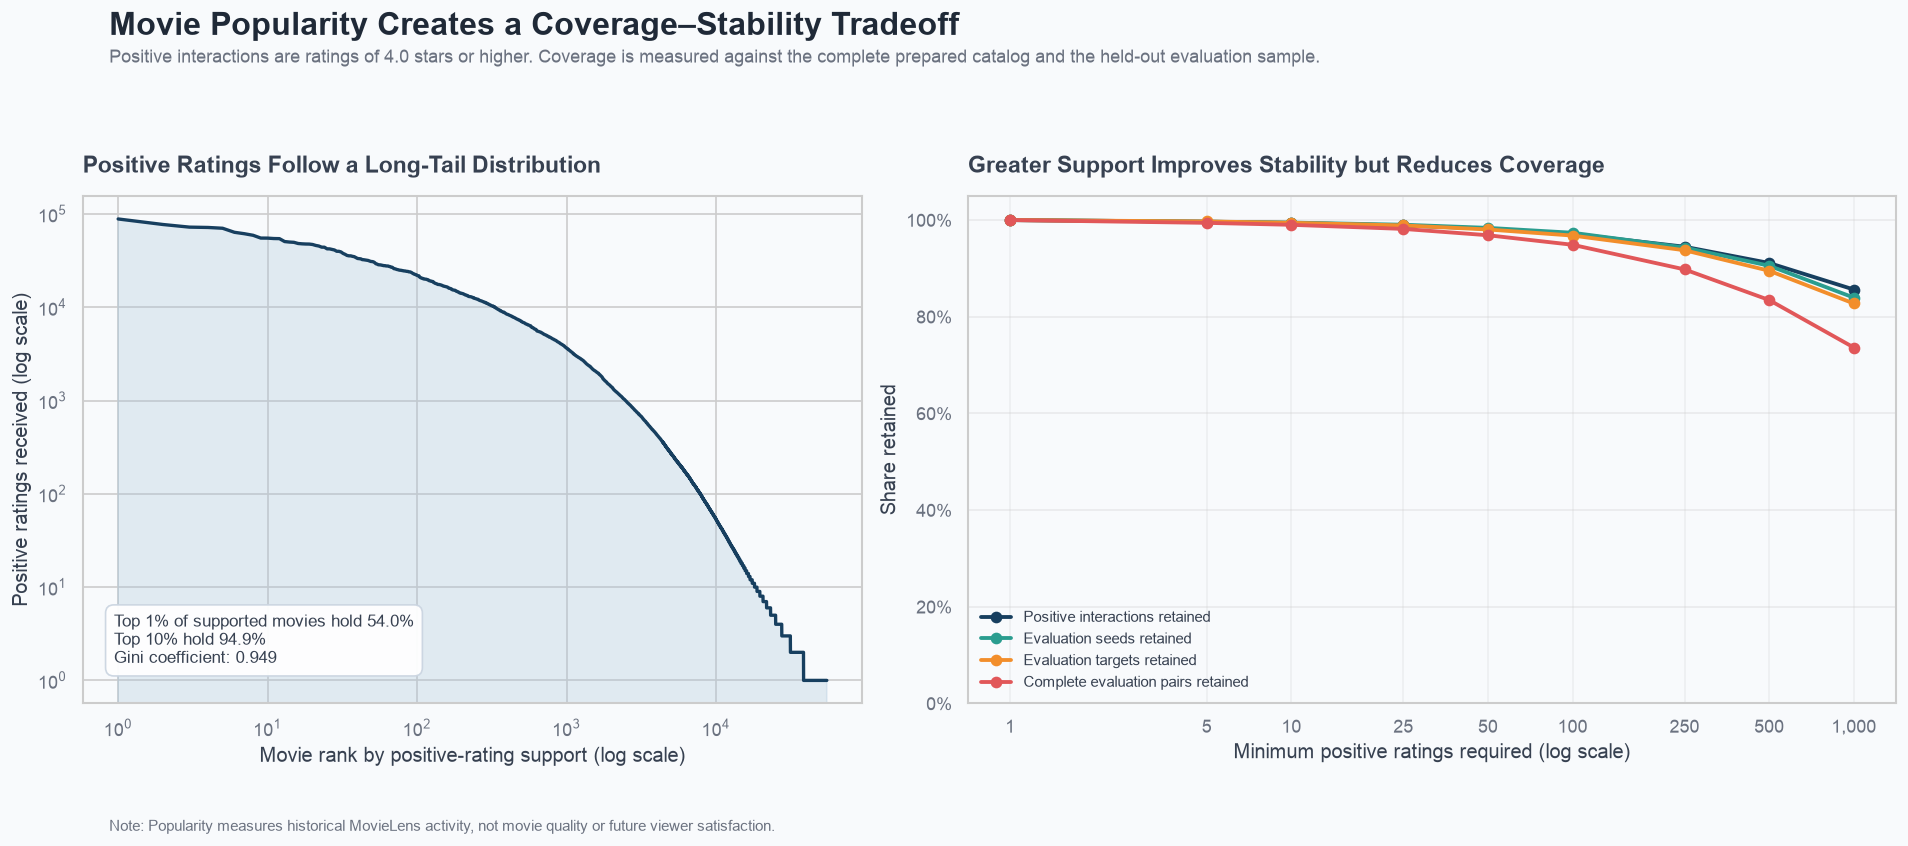

Positive-Support Concentration Summary:


,Support Measure,Result
0,Movies with at least one positive rating,"55,174"
1,Median positive ratings per supported movie,3
2,75th-percentile positive support,22
3,90th-percentile positive support,221
4,Movies in the top 1%,552
5,Positive interactions held by the top 1%,54.01%
6,Movies in the top 10%,"5,518"
7,Positive interactions held by the top 10%,94.93%
8,Gini coefficient of positive support,0.949



Minimum-Support Coverage Comparison:


,Minimum Positive Ratings,Eligible Movies,Catalog Coverage,Positive Interaction Coverage,Evaluation Seed Coverage,Evaluation Target Coverage,Complete Pair Coverage
0,1,"55,174",62.99%,100.00%,100.00%,100.00%,100.00%
1,5,"25,055",28.61%,99.67%,99.67%,99.71%,99.42%
2,10,"18,797",21.46%,99.41%,99.48%,99.43%,99.02%
3,25,"13,289",15.17%,98.88%,99.03%,98.89%,98.17%
4,50,"10,281",11.74%,98.22%,98.39%,98.06%,96.86%
5,100,"7,859",8.97%,97.15%,97.37%,96.79%,94.89%
6,250,"5,214",5.95%,94.49%,94.32%,93.76%,89.79%
7,500,"3,712",4.24%,91.12%,90.55%,89.51%,83.46%
8,1000,"2,485",2.84%,85.63%,83.96%,82.74%,73.63%



Ten Movies With the Most Positive-Rating Support:


,Movie,Positive Ratings,Total Ratings,Mean Rating,Genres
0,"Shawshank Redemption, The (1994)","88,753","102,929",4.40,Crime|Drama
1,Pulp Fiction (1994),"77,378","98,409",4.20,Comedy|Crime|Drama|Thriller
2,Forrest Gump (1994),"72,552","100,296",4.05,Comedy|Drama|Romance|War
3,"Matrix, The (1999)","71,950","93,808",4.16,Action|Sci-Fi|Thriller
4,"Silence of the Lambs, The (1991)","70,553","90,330",4.15,Crime|Horror|Thriller
5,Star Wars: Episode IV - A New Hope (1977),"63,859","85,010",4.10,Action|Adventure|Sci-Fi
6,Fight Club (1999),"61,636","77,332",4.23,Action|Crime|Drama|Thriller
7,Schindler's List (1993),"59,310","73,849",4.24,Drama|War
8,"Usual Suspects, The (1995)","55,375","67,750",4.27,Crime|Mystery|Thriller
9,Star Wars: Episode V - The Empire Strikes Back (1980),"55,305","72,151",4.13,Action|Adventure|Sci-Fi



Saved visual: outputs/MovieLens_Support_Coverage_Tradeoff.png


In [5]:
# I am verifying this analytical stage before interpreting its evidence.
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#374151",
        "text.color": "#374151",
        "xtick.color": "#6B7280",
        "ytick.color": "#6B7280",
        "font.size": 10,
    }
)
positive_movie_support = (
    movies_clean.loc[
        movies_clean["positive_rating_count"] > 0,
        [
            "movieId",
            "display_title",
            "genres",
            "rating_count",
            "positive_rating_count",
            "mean_rating",
        ],
    ]
    .sort_values("positive_rating_count", ascending=False)
    .reset_index(drop=True)
)
positive_movie_support["support_rank"] = np.arange(1, len(positive_movie_support) + 1)
positive_movie_support["cumulative_positive_interactions"] = positive_movie_support[
    "positive_rating_count"
].cumsum()
positive_movie_support["cumulative_interaction_share"] = (
    positive_movie_support["cumulative_positive_interactions"] / positive_interaction_count
)
number_of_positive_movies = len(positive_movie_support)
top_one_percent_movie_count = max(1, int(np.ceil(number_of_positive_movies * 0.01)))
top_ten_percent_movie_count = max(1, int(np.ceil(number_of_positive_movies * 0.1)))
top_one_percent_interaction_share = (
    positive_movie_support["positive_rating_count"].head(top_one_percent_movie_count).sum()
    / positive_interaction_count
)
top_ten_percent_interaction_share = (
    positive_movie_support["positive_rating_count"].head(top_ten_percent_movie_count).sum()
    / positive_interaction_count
)
sorted_support_values = np.sort(
    positive_movie_support["positive_rating_count"].to_numpy(dtype=np.float64)
)
support_index = np.arange(1, len(sorted_support_values) + 1, dtype=np.float64)
support_gini_coefficient = 2 * np.sum(support_index * sorted_support_values) / (
    len(sorted_support_values) * sorted_support_values.sum()
) - (len(sorted_support_values) + 1) / len(sorted_support_values)
support_thresholds = np.array([1, 5, 10, 25, 50, 100, 250, 500, 1000], dtype=np.int64)
evaluation_seed_movie_ids = evaluation_pairs["seed_movieId"].to_numpy(dtype=np.int64)
evaluation_target_movie_ids = evaluation_pairs["target_movieId"].to_numpy(dtype=np.int64)
support_threshold_rows = []
for minimum_support in support_thresholds:
    eligible_movie_lookup = movie_positive_rating_counts >= minimum_support
    eligible_movie_count = int(eligible_movie_lookup.sum())
    eligible_positive_interactions = int(movie_positive_rating_counts[eligible_movie_lookup].sum())
    seed_is_eligible = eligible_movie_lookup[evaluation_seed_movie_ids]
    target_is_eligible = eligible_movie_lookup[evaluation_target_movie_ids]
    support_threshold_rows.append(
        {
            "Minimum_Positive_Support": minimum_support,
            "Eligible_Movies": eligible_movie_count,
            "Catalog_Coverage": eligible_movie_count / len(movies_clean),
            "Positive_Interaction_Coverage": eligible_positive_interactions
            / positive_interaction_count,
            "Evaluation_Seed_Coverage": seed_is_eligible.mean(),
            "Evaluation_Target_Coverage": target_is_eligible.mean(),
            "Complete_Pair_Coverage": (seed_is_eligible & target_is_eligible).mean(),
        }
    )
support_threshold_summary = pd.DataFrame(support_threshold_rows)
support_threshold_display = support_threshold_summary.copy()
support_threshold_display["Eligible_Movies"] = support_threshold_display["Eligible_Movies"].map(
    lambda value: f"{value:,}"
)
percentage_columns = [
    "Catalog_Coverage",
    "Positive_Interaction_Coverage",
    "Evaluation_Seed_Coverage",
    "Evaluation_Target_Coverage",
    "Complete_Pair_Coverage",
]
for percentage_column in percentage_columns:
    support_threshold_display[percentage_column] = support_threshold_display[percentage_column].map(
        lambda value: f"{value:.2%}"
    )
support_threshold_display = support_threshold_display.rename(
    columns={
        "Minimum_Positive_Support": "Minimum Positive Ratings",
        "Eligible_Movies": "Eligible Movies",
        "Catalog_Coverage": "Catalog Coverage",
        "Positive_Interaction_Coverage": "Positive Interaction Coverage",
        "Evaluation_Seed_Coverage": "Evaluation Seed Coverage",
        "Evaluation_Target_Coverage": "Evaluation Target Coverage",
        "Complete_Pair_Coverage": "Complete Pair Coverage",
    }
)
support_concentration_summary = pd.DataFrame(
    {
        "Support Measure": [
            "Movies with at least one positive rating",
            "Median positive ratings per supported movie",
            "75th-percentile positive support",
            "90th-percentile positive support",
            "Movies in the top 1%",
            "Positive interactions held by the top 1%",
            "Movies in the top 10%",
            "Positive interactions held by the top 10%",
            "Gini coefficient of positive support",
        ],
        "Result": [
            f"{number_of_positive_movies:,}",
            f"{positive_movie_support['positive_rating_count'].median():,.0f}",
            f"{positive_movie_support['positive_rating_count'].quantile(0.75):,.0f}",
            f"{positive_movie_support['positive_rating_count'].quantile(0.9):,.0f}",
            f"{top_one_percent_movie_count:,}",
            f"{top_one_percent_interaction_share:.2%}",
            f"{top_ten_percent_movie_count:,}",
            f"{top_ten_percent_interaction_share:.2%}",
            f"{support_gini_coefficient:.3f}",
        ],
    }
)
top_supported_movies = (
    positive_movie_support[
        ["display_title", "positive_rating_count", "rating_count", "mean_rating", "genres"]
    ]
    .head(10)
    .copy()
)
top_supported_movies["positive_rating_count"] = top_supported_movies["positive_rating_count"].map(
    lambda value: f"{value:,}"
)
top_supported_movies["rating_count"] = top_supported_movies["rating_count"].map(
    lambda value: f"{value:,}"
)
top_supported_movies["mean_rating"] = top_supported_movies["mean_rating"].map(
    lambda value: f"{value:.2f}"
)
top_supported_movies = top_supported_movies.rename(
    columns={
        "display_title": "Movie",
        "positive_rating_count": "Positive Ratings",
        "rating_count": "Total Ratings",
        "mean_rating": "Mean Rating",
        "genres": "Genres",
    }
)
assert positive_movie_support["positive_rating_count"].sum() == positive_interaction_count
assert number_of_positive_movies == movies_clean["has_positive_history"].sum()
assert support_threshold_summary["Eligible_Movies"].is_monotonic_decreasing
assert support_threshold_summary["Positive_Interaction_Coverage"].is_monotonic_decreasing
assert support_threshold_summary["Complete_Pair_Coverage"].between(0, 1).all()
assert top_supported_movies["Movie"].nunique() == len(top_supported_movies)
figure, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.05, 1.25]})
figure.patch.set_facecolor("#F8FAFC")
for axis in axes:
    axis.set_facecolor("#F8FAFC")
axes[0].plot(
    positive_movie_support["support_rank"],
    positive_movie_support["positive_rating_count"],
    color="#173F5F",
    linewidth=2,
)
axes[0].fill_between(
    positive_movie_support["support_rank"].to_numpy(),
    positive_movie_support["positive_rating_count"].to_numpy(),
    color="#A9C5DA",
    alpha=0.3,
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(
    "Positive Ratings Follow a Long-Tail Distribution", loc="left", fontsize=14, pad=14
)
axes[0].set_xlabel("Movie rank by positive-rating support (log scale)")
axes[0].set_ylabel("Positive ratings received (log scale)")
axes[0].text(
    0.04,
    0.08,
    f"Top 1% of supported movies hold {top_one_percent_interaction_share:.1%}\nTop 10% hold {top_ten_percent_interaction_share:.1%}\nGini coefficient: {support_gini_coefficient:.3f}",
    transform=axes[0].transAxes,
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.95},
)
coverage_lines = [
    ("Positive interactions retained", "Positive_Interaction_Coverage", "#173F5F"),
    ("Evaluation seeds retained", "Evaluation_Seed_Coverage", "#2A9D8F"),
    ("Evaluation targets retained", "Evaluation_Target_Coverage", "#F28E2B"),
    ("Complete evaluation pairs retained", "Complete_Pair_Coverage", "#E15759"),
]
for line_label, coverage_column, line_color in coverage_lines:
    axes[1].plot(
        support_threshold_summary["Minimum_Positive_Support"],
        support_threshold_summary[coverage_column],
        marker="o",
        markersize=6,
        linewidth=2.3,
        color=line_color,
        label=line_label,
    )
axes[1].set_xscale("log")
axes[1].set_ylim(0, 1.05)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set_title(
    "Greater Support Improves Stability but Reduces Coverage", loc="left", fontsize=14, pad=14
)
axes[1].set_xlabel("Minimum positive ratings required (log scale)")
axes[1].set_ylabel("Share retained")
axes[1].set_xticks(support_thresholds)
axes[1].set_xticklabels([f"{value:,}" for value in support_thresholds])
axes[1].legend(frameon=False, loc="lower left", fontsize=9)
axes[1].grid(axis="x", alpha=0.25)
axes[1].grid(axis="y", alpha=0.35)
figure.suptitle(
    "Movie Popularity Creates a Coverage–Stability Tradeoff",
    x=0.06,
    y=1.03,
    ha="left",
    fontsize=19,
    fontweight="bold",
    color="#1F2937",
)
figure.text(
    0.06,
    0.965,
    "Positive interactions are ratings of 4.0 stars or higher. Coverage is measured against the complete prepared catalog and the held-out evaluation sample.",
    ha="left",
    fontsize=10.5,
    color="#6B7280",
)
figure.text(
    0.06,
    -0.02,
    "Note: Popularity measures historical MovieLens activity, not movie quality or future viewer satisfaction.",
    ha="left",
    fontsize=9,
    color="#6B7280",
)
plt.tight_layout(rect=[0, 0.04, 1, 0.93])
output_folder = Path("outputs")
output_folder.mkdir(parents=True, exist_ok=True)
support_visual_path = output_folder / "MovieLens_Support_Coverage_Tradeoff.png"
figure.savefig(support_visual_path, dpi=300, bbox_inches="tight", facecolor=figure.get_facecolor())
plt.show()
print("Positive-Support Concentration Summary:")
display(support_concentration_summary)
print("\nMinimum-Support Coverage Comparison:")
display(support_threshold_display)
print("\nTen Movies With the Most Positive-Rating Support:")
display(top_supported_movies)
print(f"\nSaved visual: {support_visual_path}")


### Section 4 Interpretation
The positive-interaction distribution is extremely concentrated. Although 55,174 movies received at least one positive rating, the median supported movie received only three. The top 1% of movies account for 54.01% of all positive interactions, while the top 10% account for 94.93%. The Gini coefficient of 0.949 confirms a highly unequal long-tail distribution. This means raw popularity will be a competitive but narrow baseline that favors already prominent movies.

A minimum support of 25 positive ratings provides the best starting balance. It retains 13,289 movies, 98.88% of positive interactions, and 98.17% of complete evaluation pairs. Raising the requirement to 100 reduces complete-pair coverage to 94.89% and leaves only 7,859 movies. I will therefore build the base training matrix at 25 interactions while retaining the ability to test stricter thresholds later.

## Section 5: Held-Target-Excluded Training Matrix and Popularity Baseline

Based on the support analysis, I use 25 positive training interactions as the initial movie-support requirement. Before applying this requirement, I subtract every held-out evaluation target from its user’s training history. This prevents the test preference from influencing movie eligibility, popularity, or collaborative-filtering features.

I first evaluate a global popularity baseline. This baseline recommends the most frequently liked training movies and ignores the selected seed movie except for removing it from the recommendation list. A collaborative model should outperform this baseline by using relationships between movies rather than simply recommending the same popular titles to everyone.

In [6]:
# I am verifying this analytical stage before interpreting its evidence.
import gc
from scipy.sparse import coo_matrix

base_minimum_positive_support = 25
recommendation_list_length = 10
heldout_target_counts = np.bincount(
    evaluation_pairs["target_movieId"].to_numpy(dtype=np.int64),
    minlength=len(movie_positive_rating_counts),
)
training_positive_rating_counts = movie_positive_rating_counts - heldout_target_counts
if (training_positive_rating_counts < 0).any():
    raise ValueError("A held-out count exceeded the original positive-interaction count.")
eligible_model_movie_ids = np.flatnonzero(
    training_positive_rating_counts >= base_minimum_positive_support
)
number_of_model_movies = len(eligible_model_movie_ids)
movie_id_to_model_index = np.full(len(training_positive_rating_counts), -1, dtype=np.int32)
movie_id_to_model_index[eligible_model_movie_ids] = np.arange(
    number_of_model_movies, dtype=np.int32
)
training_movie_index_parts = []
training_user_id_parts = []
for rating_chunk in pd.read_csv(
    ratings_path,
    usecols=["userId", "movieId", "rating"],
    dtype={"userId": "int32", "movieId": "int32", "rating": "float32"},
    chunksize=ratings_chunk_size,
):
    chunk_user_ids = rating_chunk["userId"].to_numpy(dtype=np.int64)
    chunk_movie_ids = rating_chunk["movieId"].to_numpy(dtype=np.int64)
    chunk_ratings = rating_chunk["rating"].to_numpy(dtype=np.float32)
    positive_mask = chunk_ratings >= positive_rating_threshold
    chunk_model_movie_indices = movie_id_to_model_index[chunk_movie_ids]
    eligible_movie_mask = chunk_model_movie_indices >= 0
    heldout_interaction_mask = heldout_target_by_user[chunk_user_ids] == chunk_movie_ids
    training_mask = positive_mask & eligible_movie_mask & ~heldout_interaction_mask
    if training_mask.any():
        training_movie_index_parts.append(
            chunk_model_movie_indices[training_mask].astype(np.int32, copy=False)
        )
        training_user_id_parts.append(chunk_user_ids[training_mask].astype(np.int32, copy=False))
training_movie_indices = np.concatenate(training_movie_index_parts)
training_user_ids = np.concatenate(training_user_id_parts)
training_values = np.ones(len(training_movie_indices), dtype=np.float32)
item_user_training_matrix = coo_matrix(
    (training_values, (training_movie_indices, training_user_ids)),
    shape=(number_of_model_movies, len(user_rating_counts)),
    dtype=np.float32,
).tocsr()
item_user_training_matrix.sort_indices()
del training_movie_index_parts
del training_user_id_parts
del training_movie_indices
del training_user_ids
del training_values
gc.collect()
expected_training_support = training_positive_rating_counts[eligible_model_movie_ids]
observed_training_support = (
    np.asarray(item_user_training_matrix.sum(axis=1)).ravel().astype(np.int64)
)
evaluation_seed_model_indices = movie_id_to_model_index[
    evaluation_pairs["seed_movieId"].to_numpy(dtype=np.int64)
]
evaluation_target_model_indices = movie_id_to_model_index[
    evaluation_pairs["target_movieId"].to_numpy(dtype=np.int64)
]
model_evaluation_mask = (evaluation_seed_model_indices >= 0) & (
    evaluation_target_model_indices >= 0
)
model_evaluation_pairs = evaluation_pairs.loc[model_evaluation_mask].copy().reset_index(drop=True)
model_evaluation_pairs["seed_model_index"] = evaluation_seed_model_indices[model_evaluation_mask]
model_evaluation_pairs["target_model_index"] = evaluation_target_model_indices[
    model_evaluation_mask
]
model_pair_coverage = len(model_evaluation_pairs) / len(evaluation_pairs)
eligible_training_support = training_positive_rating_counts[eligible_model_movie_ids]
popularity_sort_order = np.lexsort((eligible_model_movie_ids, -eligible_training_support))
popularity_ranked_movie_ids = eligible_model_movie_ids[popularity_sort_order]
popularity_ranked_support = eligible_training_support[popularity_sort_order]
popularity_candidate_pool = popularity_ranked_movie_ids[: recommendation_list_length + 1]
baseline_target_ranks = []
baseline_unique_recommendations = set()
for evaluation_row in model_evaluation_pairs.itertuples(index=False):
    seed_movie_id = int(evaluation_row.seed_movieId)
    target_movie_id = int(evaluation_row.target_movieId)
    baseline_recommendations = popularity_candidate_pool[
        popularity_candidate_pool != seed_movie_id
    ][:recommendation_list_length]
    baseline_unique_recommendations.update(baseline_recommendations.tolist())
    target_locations = np.flatnonzero(baseline_recommendations == target_movie_id)
    if len(target_locations) == 0:
        baseline_target_ranks.append(0)
    else:
        baseline_target_ranks.append(int(target_locations[0] + 1))
baseline_target_ranks = np.asarray(baseline_target_ranks, dtype=np.int16)
baseline_hit_mask = baseline_target_ranks > 0
baseline_hit_count = int(baseline_hit_mask.sum())
baseline_conditional_hit_rate = baseline_hit_mask.mean()
baseline_mrr_at_10 = np.mean(
    np.where(baseline_hit_mask, 1 / np.maximum(baseline_target_ranks, 1), 0)
)
baseline_ndcg_at_10 = np.mean(
    np.where(baseline_hit_mask, 1 / np.log2(baseline_target_ranks + 1), 0)
)
baseline_recall_at_10 = baseline_conditional_hit_rate
baseline_coverage_adjusted_hit_rate = baseline_hit_count / len(evaluation_pairs)
baseline_recommendation_catalog_coverage = (
    len(baseline_unique_recommendations) / number_of_model_movies
)
confidence_z = 1.96
baseline_evaluation_count = len(model_evaluation_pairs)
wilson_denominator = 1 + confidence_z**2 / baseline_evaluation_count
wilson_center = (
    baseline_conditional_hit_rate + confidence_z**2 / (2 * baseline_evaluation_count)
) / wilson_denominator
wilson_margin = (
    confidence_z
    * np.sqrt(
        baseline_conditional_hit_rate
        * (1 - baseline_conditional_hit_rate)
        / baseline_evaluation_count
        + confidence_z**2 / (4 * baseline_evaluation_count**2)
    )
    / wilson_denominator
)
baseline_hit_rate_lower = wilson_center - wilson_margin
baseline_hit_rate_upper = wilson_center + wilson_margin
baseline_movie_table = pd.DataFrame(
    {
        "movieId": popularity_ranked_movie_ids[:recommendation_list_length],
        "Training_Positive_Ratings": popularity_ranked_support[:recommendation_list_length],
    }
).merge(
    movies_clean[["movieId", "display_title", "genres", "mean_rating"]],
    on="movieId",
    how="left",
    validate="one_to_one",
)
baseline_movie_table["Rank"] = np.arange(1, len(baseline_movie_table) + 1)
baseline_movie_table = baseline_movie_table[
    ["Rank", "display_title", "Training_Positive_Ratings", "mean_rating", "genres"]
].rename(
    columns={
        "display_title": "Movie",
        "Training_Positive_Ratings": "Training Positive Ratings",
        "mean_rating": "Historical Mean Rating",
        "genres": "Genres",
    }
)
baseline_movie_table["Training Positive Ratings"] = baseline_movie_table[
    "Training Positive Ratings"
].map(lambda value: f"{value:,}")
baseline_movie_table["Historical Mean Rating"] = baseline_movie_table["Historical Mean Rating"].map(
    lambda value: f"{value:.2f}"
)
matrix_memory_bytes = (
    item_user_training_matrix.data.nbytes
    + item_user_training_matrix.indices.nbytes
    + item_user_training_matrix.indptr.nbytes
)
matrix_density = item_user_training_matrix.nnz / (
    item_user_training_matrix.shape[0] * item_user_training_matrix.shape[1]
)
heldout_targets_removed_from_eligible_movies = int(
    heldout_target_counts[eligible_model_movie_ids].sum()
)
training_matrix_summary = pd.DataFrame(
    {
        "Training Measure": [
            "Minimum positive training support",
            "Eligible model movies",
            "Training users represented by matrix columns",
            "Training positive interactions",
            "Held-out targets removed from eligible movies",
            "Sparse matrix rows",
            "Sparse matrix columns",
            "Sparse matrix density",
            "Sparse matrix memory",
            "Complete evaluation pairs",
            "Complete-pair coverage",
        ],
        "Result": [
            f"{base_minimum_positive_support:,}",
            f"{number_of_model_movies:,}",
            f"{item_user_training_matrix.shape[1]:,}",
            f"{item_user_training_matrix.nnz:,}",
            f"{heldout_targets_removed_from_eligible_movies:,}",
            f"{item_user_training_matrix.shape[0]:,}",
            f"{item_user_training_matrix.shape[1]:,}",
            f"{matrix_density:.6%}",
            f"{matrix_memory_bytes / 1024 ** 2:,.2f} MB",
            f"{len(model_evaluation_pairs):,}",
            f"{model_pair_coverage:.2%}",
        ],
    }
)
baseline_performance_summary = pd.DataFrame(
    {
        "Baseline Measure": [
            "Method",
            "Recommendation length",
            "Conditional Hit Rate@10",
            "Hit Rate@10 95% CI lower",
            "Hit Rate@10 95% CI upper",
            "Recall@10",
            "MRR@10",
            "NDCG@10",
            "Coverage-adjusted Hit Rate@10",
            "Recommendation catalog coverage",
        ],
        "Result": [
            "Training-only global popularity",
            recommendation_list_length,
            f"{baseline_conditional_hit_rate:.3%}",
            f"{baseline_hit_rate_lower:.3%}",
            f"{baseline_hit_rate_upper:.3%}",
            f"{baseline_recall_at_10:.3%}",
            f"{baseline_mrr_at_10:.4f}",
            f"{baseline_ndcg_at_10:.4f}",
            f"{baseline_coverage_adjusted_hit_rate:.3%}",
            f"{baseline_recommendation_catalog_coverage:.3%}",
        ],
    }
)
assert heldout_target_counts.sum() == len(evaluation_pairs)
assert item_user_training_matrix.nnz == int(expected_training_support.sum())
assert np.array_equal(observed_training_support, expected_training_support)
assert expected_training_support.min() >= base_minimum_positive_support
assert model_evaluation_pairs["userId"].is_unique
assert baseline_target_ranks.shape[0] == len(model_evaluation_pairs)
assert 0 <= baseline_conditional_hit_rate <= 1
assert 0 <= baseline_ndcg_at_10 <= 1
print("Held-Target-Excluded Training Matrix Summary:")
display(training_matrix_summary)
print("\nPopularity Baseline Performance:")
display(baseline_performance_summary)
print("\nTen Movies Used by the Global Popularity Baseline:")
display(baseline_movie_table)
print("\nSection 5 training matrix and popularity baseline completed successfully.")


Held-Target-Excluded Training Matrix Summary:


/var/folders/3f/sfxs48p91rl1_nrch6jjj3cr0000gn/T/ipykernel_92208/2948047338.py:104: RuntimeWarning: divide by zero encountered in divide
  np.where(baseline_hit_mask, 1 / np.log2(baseline_target_ranks + 1), 0)


,Training Measure,Result
0,Minimum positive training support,25
1,Eligible model movies,"13,280"
2,Training users represented by matrix columns,"200,949"
3,Training positive interactions,"15,740,145"
4,Held-out targets removed from eligible movies,"19,719"
5,Sparse matrix rows,"13,280"
6,Sparse matrix columns,"200,949"
7,Sparse matrix density,0.589827%
8,Sparse matrix memory,120.14 MB
9,Complete evaluation pairs,"19,576"



Popularity Baseline Performance:


,Baseline Measure,Result
0,Method,Training-only global popularity
1,Recommendation length,10
2,Conditional Hit Rate@10,3.228%
3,Hit Rate@10 95% CI lower,2.990%
4,Hit Rate@10 95% CI upper,3.485%
5,Recall@10,3.228%
6,MRR@10,0.0106
7,NDCG@10,0.0156
8,Coverage-adjusted Hit Rate@10,3.168%
9,Recommendation catalog coverage,0.083%



Ten Movies Used by the Global Popularity Baseline:


,Rank,Movie,Training Positive Ratings,Historical Mean Rating,Genres
0,1,"Shawshank Redemption, The (1994)","88,666",4.40,Crime|Drama
1,2,Pulp Fiction (1994),"77,310",4.20,Comedy|Crime|Drama|Thriller
2,3,Forrest Gump (1994),"72,488",4.05,Comedy|Drama|Romance|War
3,4,"Matrix, The (1999)","71,897",4.16,Action|Sci-Fi|Thriller
4,5,"Silence of the Lambs, The (1991)","70,485",4.15,Crime|Horror|Thriller
5,6,Star Wars: Episode IV - A New Hope (1977),"63,827",4.10,Action|Adventure|Sci-Fi
6,7,Fight Club (1999),"61,571",4.23,Action|Crime|Drama|Thriller
7,8,Schindler's List (1993),"59,229",4.24,Drama|War
8,9,"Usual Suspects, The (1995)","55,308",4.27,Crime|Mystery|Thriller
9,10,Star Wars: Episode V - The Empire Strikes Back (1980),"55,262",4.13,Action|Adventure|Sci-Fi



Section 5 training matrix and popularity baseline completed successfully.


### Interpretation
After removing the held-out targets, 13,280 movies still met the minimum requirement of 25 positive training ratings. The sparse matrix retained 15,740,145 positive interactions while using only 120.14 MB, making the full MovieLens 32M data computationally manageable. The model can evaluate 19,576 of the 19,950 eligible seed–target pairs, providing strong coverage of 98.13%. The slight decline from the earlier coverage estimate is expected because eligibility was recalculated using training data only, which prevents information from the held-out targets from leaking into model construction.

The popularity baseline correctly establishes a modest benchmark. It identified the held-out movie within its ten recommendations for only 3.228% of covered cases, with a 95% confidence interval from 2.990% to 3.485%. Its MRR@10 of 0.0106 and NDCG@10 of 0.0156 also show that correct targets were rarely found and were not consistently placed near the top of the list. Most importantly, this approach covered only 0.083% of the eligible recommendation catalog because it repeatedly recommended nearly the same globally popular movies. This confirms that popularity alone offers very little personalization or discovery. The collaborative model should therefore be judged on whether it improves ranking accuracy and recommendation diversity beyond this transparent baseline.

## Section 6: Train and Validate Collaborative-Filtering Models
This section creates a user-level validation and final-test split, trains TF-IDF-weighted item-to-item collaborative models, and compares 16-, 32-, and 64-factor representations against the popularity baseline. Model selection uses validation results only. The final-test recommendations remain untouched.

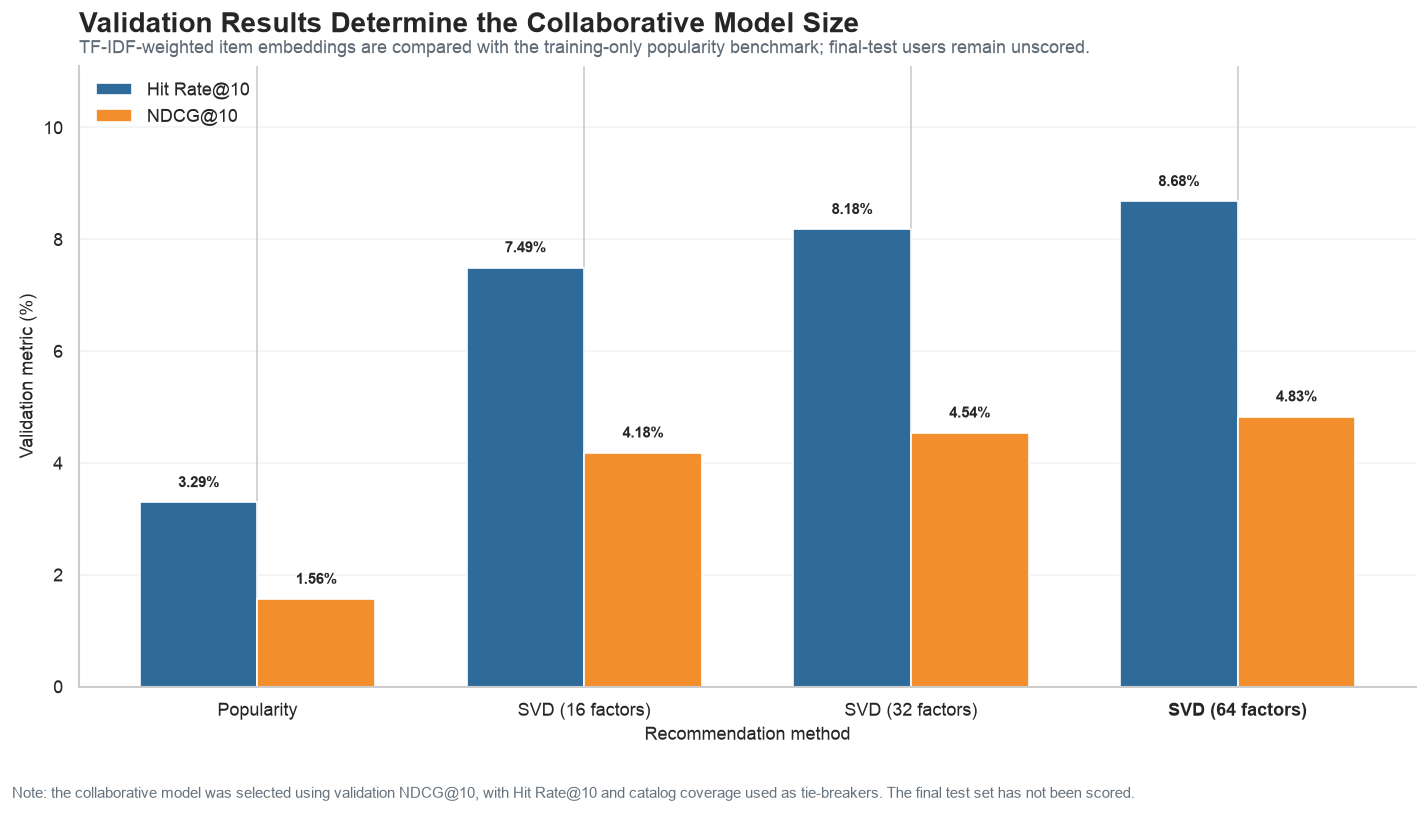

Validation and Final-Test Design:


,Validation Design Measure,Result
0,Complete prepared evaluation users,"19,950"
1,Validation users,"9,975"
2,Reserved final-test users,"9,975"
3,Covered validation pairs,"9,807"
4,Validation complete-pair coverage,98.32%
5,Candidate latent dimensions,"16, 32, 64"
6,Maximum SVD dimensions fitted,64
7,Selected validation model,TF-IDF SVD Collaborative (64 factors)
8,Selected latent dimensions,64
9,Final-test ranking metrics computed,No



Validation Model Comparison:


,Model,Validation Pairs,Pair Coverage,Hit Rate@10,95% CI Lower,95% CI Upper,MRR@10,NDCG@10,Coverage-Adjusted Hit Rate@10,Recommendation Catalog Coverage,Latent Variance Explained
0,Global Popularity Baseline,9807,98.316%,3.294%,2.958%,3.665%,0.0105,0.0156,3.238%,0.083%,Not Applicable
1,TF-IDF SVD Collaborative (16 factors),9807,98.316%,7.495%,6.990%,8.033%,0.0318,0.0418,7.368%,63.404%,4.227%
2,TF-IDF SVD Collaborative (32 factors),9807,98.316%,8.178%,7.652%,8.737%,0.0344,0.0454,8.040%,62.018%,5.792%
3,TF-IDF SVD Collaborative (64 factors),9807,98.316%,8.677%,8.136%,9.251%,0.0366,0.0483,8.531%,59.669%,7.666%



Selected Collaborative Model: TF-IDF SVD Collaborative (64 factors)
Saved visual: outputs/MovieLens_Validation_Model_Comparison.png

Section 6 model training and validation completed successfully. The final test set remains unscored.


In [7]:
# I am verifying this analytical stage before interpreting its evidence.
import gc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

model_random_seed = 530
validation_fraction = 0.5
candidate_latent_dimensions = [16, 32, 64]
maximum_latent_dimensions = max(candidate_latent_dimensions)
nearest_neighbors_requested = recommendation_list_length + 2
required_evaluation_columns = {"userId", "seed_movieId", "target_movieId"}
missing_evaluation_columns = required_evaluation_columns - set(evaluation_pairs.columns)
if missing_evaluation_columns:
    raise ValueError(
        f"The evaluation table is missing required columns: {sorted(missing_evaluation_columns)}"
    )
required_model_columns = {
    "userId",
    "seed_movieId",
    "target_movieId",
    "seed_model_index",
    "target_model_index",
}
missing_model_columns = required_model_columns - set(model_evaluation_pairs.columns)
if missing_model_columns:
    raise ValueError(
        f"The covered evaluation table is missing required columns: {sorted(missing_model_columns)}"
    )
all_evaluation_user_ids = evaluation_pairs["userId"].drop_duplicates().to_numpy(dtype=np.int32)
validation_user_ids, final_test_user_ids = train_test_split(
    all_evaluation_user_ids,
    test_size=validation_fraction,
    random_state=model_random_seed,
    shuffle=True,
)
validation_user_ids = np.sort(validation_user_ids)
final_test_user_ids = np.sort(final_test_user_ids)
validation_pairs_all = (
    evaluation_pairs.loc[evaluation_pairs["userId"].isin(validation_user_ids)]
    .copy()
    .reset_index(drop=True)
)
final_test_pairs_all = (
    evaluation_pairs.loc[evaluation_pairs["userId"].isin(final_test_user_ids)]
    .copy()
    .reset_index(drop=True)
)
validation_pairs = (
    model_evaluation_pairs.loc[model_evaluation_pairs["userId"].isin(validation_user_ids)]
    .copy()
    .reset_index(drop=True)
)
final_test_pairs = (
    model_evaluation_pairs.loc[model_evaluation_pairs["userId"].isin(final_test_user_ids)]
    .copy()
    .reset_index(drop=True)
)
validation_pair_coverage = len(validation_pairs) / len(validation_pairs_all)
assert set(validation_user_ids).isdisjoint(set(final_test_user_ids))
assert len(validation_pairs_all) + len(final_test_pairs_all) == len(evaluation_pairs)
assert validation_pairs_all["userId"].is_unique
assert final_test_pairs_all["userId"].is_unique
tfidf_transformer = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=False)
tfidf_item_user_matrix = tfidf_transformer.fit_transform(
    item_user_training_matrix.astype(np.float32, copy=False)
)
svd_model = TruncatedSVD(
    n_components=maximum_latent_dimensions,
    algorithm="randomized",
    n_iter=5,
    random_state=model_random_seed,
)
maximum_item_embeddings = svd_model.fit_transform(tfidf_item_user_matrix).astype(np.float32)
cumulative_explained_variance = np.cumsum(svd_model.explained_variance_ratio_)


def calculate_ranking_metrics(
    recommendation_movie_ids, target_movie_ids, total_evaluation_pairs, eligible_catalog_size
):
    recommendation_movie_ids = np.asarray(recommendation_movie_ids, dtype=np.int64)
    target_movie_ids = np.asarray(target_movie_ids, dtype=np.int64)
    if recommendation_movie_ids.ndim != 2:
        raise ValueError("Recommendations must be a two-dimensional array.")
    if len(recommendation_movie_ids) != len(target_movie_ids):
        raise ValueError("Recommendation rows and target rows do not match.")
    target_matches = recommendation_movie_ids == target_movie_ids[:, None]
    hit_mask = target_matches.any(axis=1)
    target_ranks = np.zeros(len(target_movie_ids), dtype=np.int16)
    target_ranks[hit_mask] = target_matches[hit_mask].argmax(axis=1) + 1
    evaluation_count = len(target_movie_ids)
    hit_count = int(hit_mask.sum())
    conditional_hit_rate = hit_count / evaluation_count
    reciprocal_rank_values = np.zeros(evaluation_count, dtype=np.float64)
    reciprocal_rank_values[hit_mask] = 1.0 / target_ranks[hit_mask]
    ndcg_values = np.zeros(evaluation_count, dtype=np.float64)
    ndcg_values[hit_mask] = 1.0 / np.log2(target_ranks[hit_mask] + 1)
    mrr_at_10 = reciprocal_rank_values.mean()
    ndcg_at_10 = ndcg_values.mean()
    pair_coverage = evaluation_count / total_evaluation_pairs
    coverage_adjusted_hit_rate = hit_count / total_evaluation_pairs
    recommendation_catalog_coverage = (
        np.unique(recommendation_movie_ids).size / eligible_catalog_size
    )
    confidence_z = 1.96
    wilson_denominator = 1 + confidence_z**2 / evaluation_count
    wilson_center = (
        conditional_hit_rate + confidence_z**2 / (2 * evaluation_count)
    ) / wilson_denominator
    wilson_margin = (
        confidence_z
        * np.sqrt(
            conditional_hit_rate * (1 - conditional_hit_rate) / evaluation_count
            + confidence_z**2 / (4 * evaluation_count**2)
        )
        / wilson_denominator
    )
    return {
        "Validation_Pairs": evaluation_count,
        "Pair_Coverage": pair_coverage,
        "Hit_Count": hit_count,
        "Hit_Rate_At_10": conditional_hit_rate,
        "Hit_Rate_CI_Lower": wilson_center - wilson_margin,
        "Hit_Rate_CI_Upper": wilson_center + wilson_margin,
        "Recall_At_10": conditional_hit_rate,
        "MRR_At_10": mrr_at_10,
        "NDCG_At_10": ndcg_at_10,
        "Coverage_Adjusted_Hit_Rate_At_10": coverage_adjusted_hit_rate,
        "Recommendation_Catalog_Coverage": recommendation_catalog_coverage,
    }


validation_seed_movie_ids = validation_pairs["seed_movieId"].to_numpy(dtype=np.int64)
validation_target_movie_ids = validation_pairs["target_movieId"].to_numpy(dtype=np.int64)
popularity_validation_recommendations = np.vstack(
    [
        popularity_candidate_pool[popularity_candidate_pool != seed_movie_id][
            :recommendation_list_length
        ]
        for seed_movie_id in validation_seed_movie_ids
    ]
)
popularity_validation_metrics = calculate_ranking_metrics(
    recommendation_movie_ids=popularity_validation_recommendations,
    target_movie_ids=validation_target_movie_ids,
    total_evaluation_pairs=len(validation_pairs_all),
    eligible_catalog_size=number_of_model_movies,
)
validation_result_rows = [
    {
        "Model": "Global Popularity Baseline",
        "Model_Family": "Baseline",
        "Latent_Dimensions": 0,
        "Explained_Variance": np.nan,
        **popularity_validation_metrics,
    }
]
candidate_item_embeddings = {}
candidate_neighbor_models = {}
for latent_dimensions in candidate_latent_dimensions:
    dimension_item_embeddings = normalize(
        maximum_item_embeddings[:, :latent_dimensions], norm="l2", axis=1, copy=True
    ).astype(np.float32, copy=False)
    neighbor_model = NearestNeighbors(
        n_neighbors=nearest_neighbors_requested, metric="cosine", algorithm="brute", n_jobs=4
    )
    neighbor_model.fit(dimension_item_embeddings)
    validation_seed_model_indices = validation_pairs["seed_model_index"].to_numpy(dtype=np.int32)
    unique_seed_model_indices, seed_inverse = np.unique(
        validation_seed_model_indices, return_inverse=True
    )
    neighbor_model_indices = neighbor_model.kneighbors(
        dimension_item_embeddings[unique_seed_model_indices], return_distance=False
    )
    unique_seed_recommendation_indices = np.vstack(
        [
            neighbor_rows[neighbor_rows != seed_model_index][:recommendation_list_length]
            for seed_model_index, neighbor_rows in zip(
                unique_seed_model_indices, neighbor_model_indices
            )
        ]
    )
    validation_recommendation_indices = unique_seed_recommendation_indices[seed_inverse]
    validation_recommendation_movie_ids = eligible_model_movie_ids[
        validation_recommendation_indices
    ]
    collaborative_metrics = calculate_ranking_metrics(
        recommendation_movie_ids=validation_recommendation_movie_ids,
        target_movie_ids=validation_target_movie_ids,
        total_evaluation_pairs=len(validation_pairs_all),
        eligible_catalog_size=number_of_model_movies,
    )
    candidate_name = f"TF-IDF SVD Collaborative ({latent_dimensions} factors)"
    validation_result_rows.append(
        {
            "Model": candidate_name,
            "Model_Family": "Collaborative Filtering",
            "Latent_Dimensions": latent_dimensions,
            "Explained_Variance": cumulative_explained_variance[latent_dimensions - 1],
            **collaborative_metrics,
        }
    )
    candidate_item_embeddings[latent_dimensions] = dimension_item_embeddings
    candidate_neighbor_models[latent_dimensions] = neighbor_model
validation_results_numeric = pd.DataFrame(validation_result_rows)
collaborative_validation_results = (
    validation_results_numeric.loc[
        validation_results_numeric["Model_Family"] == "Collaborative Filtering"
    ]
    .sort_values(
        by=["NDCG_At_10", "Hit_Rate_At_10", "Recommendation_Catalog_Coverage"],
        ascending=[False, False, False],
    )
    .reset_index(drop=True)
)
selected_validation_row = collaborative_validation_results.iloc[0]
selected_latent_dimension = int(selected_validation_row["Latent_Dimensions"])
selected_validation_model = selected_validation_row["Model"]
selected_item_embeddings = candidate_item_embeddings[selected_latent_dimension]
selected_neighbor_model = candidate_neighbor_models[selected_latent_dimension]
validation_results_display = validation_results_numeric[
    [
        "Model",
        "Validation_Pairs",
        "Pair_Coverage",
        "Hit_Rate_At_10",
        "Hit_Rate_CI_Lower",
        "Hit_Rate_CI_Upper",
        "MRR_At_10",
        "NDCG_At_10",
        "Coverage_Adjusted_Hit_Rate_At_10",
        "Recommendation_Catalog_Coverage",
        "Explained_Variance",
    ]
].copy()
percentage_columns = [
    "Pair_Coverage",
    "Hit_Rate_At_10",
    "Hit_Rate_CI_Lower",
    "Hit_Rate_CI_Upper",
    "Coverage_Adjusted_Hit_Rate_At_10",
    "Recommendation_Catalog_Coverage",
    "Explained_Variance",
]
for column_name in percentage_columns:
    validation_results_display[column_name] = validation_results_display[column_name].map(
        lambda value: "Not Applicable" if pd.isna(value) else f"{value:.3%}"
    )
for column_name in ["MRR_At_10", "NDCG_At_10"]:
    validation_results_display[column_name] = validation_results_display[column_name].map(
        lambda value: f"{value:.4f}"
    )
validation_results_display = validation_results_display.rename(
    columns={
        "Validation_Pairs": "Validation Pairs",
        "Pair_Coverage": "Pair Coverage",
        "Hit_Rate_At_10": "Hit Rate@10",
        "Hit_Rate_CI_Lower": "95% CI Lower",
        "Hit_Rate_CI_Upper": "95% CI Upper",
        "MRR_At_10": "MRR@10",
        "NDCG_At_10": "NDCG@10",
        "Coverage_Adjusted_Hit_Rate_At_10": "Coverage-Adjusted Hit Rate@10",
        "Recommendation_Catalog_Coverage": "Recommendation Catalog Coverage",
        "Explained_Variance": "Latent Variance Explained",
    }
)
validation_design_summary = pd.DataFrame(
    {
        "Validation Design Measure": [
            "Complete prepared evaluation users",
            "Validation users",
            "Reserved final-test users",
            "Covered validation pairs",
            "Validation complete-pair coverage",
            "Candidate latent dimensions",
            "Maximum SVD dimensions fitted",
            "Selected validation model",
            "Selected latent dimensions",
            "Final-test ranking metrics computed",
        ],
        "Result": [
            f"{len(evaluation_pairs):,}",
            f"{len(validation_pairs_all):,}",
            f"{len(final_test_pairs_all):,}",
            f"{len(validation_pairs):,}",
            f"{validation_pair_coverage:.2%}",
            ", ".join((str(value) for value in candidate_latent_dimensions)),
            maximum_latent_dimensions,
            selected_validation_model,
            selected_latent_dimension,
            "No",
        ],
    }
)
comparison_plot_data = validation_results_numeric.copy()
comparison_plot_data["Short_Model"] = (
    comparison_plot_data["Model"]
    .str.replace("TF-IDF SVD Collaborative ", "SVD ", regex=False)
    .str.replace("Global Popularity Baseline", "Popularity", regex=False)
)
sns.set_theme(style="whitegrid", context="notebook")
figure, axis = plt.subplots(figsize=(12, 6.8))
model_positions = np.arange(len(comparison_plot_data))
bar_width = 0.36
hit_rate_bars = axis.bar(
    model_positions - bar_width / 2,
    comparison_plot_data["Hit_Rate_At_10"] * 100,
    width=bar_width,
    color="#2F6B9A",
    label="Hit Rate@10",
)
ndcg_bars = axis.bar(
    model_positions + bar_width / 2,
    comparison_plot_data["NDCG_At_10"] * 100,
    width=bar_width,
    color="#F28E2B",
    label="NDCG@10",
)
axis.set_title(
    "Validation Results Determine the Collaborative Model Size",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=20,
)
axis.text(
    0,
    1.02,
    "TF-IDF-weighted item embeddings are compared with the training-only popularity benchmark; final-test users remain unscored.",
    transform=axis.transAxes,
    fontsize=10.5,
    color="#5E6A75",
)
axis.set_ylabel("Validation metric (%)", fontsize=11)
axis.set_xlabel("Recommendation method", fontsize=11)
axis.set_xticks(model_positions)
axis.set_xticklabels(comparison_plot_data["Short_Model"])
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.grid(axis="y", alpha=0.22)
axis.legend(frameon=False, loc="upper left")
largest_metric = float(
    comparison_plot_data[["Hit_Rate_At_10", "NDCG_At_10"]].to_numpy().max() * 100
)
axis.set_ylim(0, max(largest_metric * 1.28, 1))
for bar_collection in [hit_rate_bars, ndcg_bars]:
    for bar in bar_collection:
        bar_height = bar.get_height()
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar_height + largest_metric * 0.025,
            f"{bar_height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )
selected_plot_position = int(
    comparison_plot_data.index[comparison_plot_data["Model"] == selected_validation_model][0]
)
axis.get_xticklabels()[selected_plot_position].set_fontweight("bold")
figure.text(
    0.01,
    0.01,
    "Note: the collaborative model was selected using validation NDCG@10, with Hit Rate@10 and catalog coverage used as tie-breakers. The final test set has not been scored.",
    fontsize=9,
    color="#66727D",
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
movie_lens_output_folder = Path("outputs")
movie_lens_output_folder.mkdir(parents=True, exist_ok=True)
validation_comparison_path = movie_lens_output_folder / "MovieLens_Validation_Model_Comparison.png"
figure.savefig(validation_comparison_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
metric_columns = [
    "Hit_Rate_At_10",
    "MRR_At_10",
    "NDCG_At_10",
    "Coverage_Adjusted_Hit_Rate_At_10",
    "Recommendation_Catalog_Coverage",
]
assert validation_results_numeric[metric_columns].ge(0).all().all()
assert validation_results_numeric[metric_columns].le(1).all().all()
assert validation_pairs["userId"].is_unique
assert final_test_pairs_all["userId"].is_unique
assert selected_validation_model in validation_results_numeric["Model"].tolist()
del tfidf_item_user_matrix
del maximum_item_embeddings
del candidate_item_embeddings
del candidate_neighbor_models
gc.collect()
print("Validation and Final-Test Design:")
display(validation_design_summary)
print("\nValidation Model Comparison:")
display(validation_results_display)
print(f"\nSelected Collaborative Model: {selected_validation_model}")
print(f"Saved visual: {validation_comparison_path}")
print(
    "\nSection 6 model training and validation completed successfully. The final test set remains unscored."
)


### Interpretation

The validation set contained 9,975 users, and 9,807 seed–target pairs were covered by the support-qualified catalog, providing 98.32% coverage. Performance improved consistently as the latent representation increased. Hit Rate@10 rose from 7.495% with 16 factors to 8.178% with 32 factors and 8.677% with 64 factors. The 64-factor model’s 95% confidence interval ranged from 8.136% to 9.251%, compared with 2.958% to 3.665% for the popularity baseline. Its NDCG@10 also increased to 0.0483, confirming that it retrieved more held-out movies and generally placed them higher in the recommendation list.

The selected 64-factor collaborative model produced a 5.383-percentage-point improvement over the baseline Hit Rate@10, equivalent to a relative increase of approximately 163%. It also recommended from 59.669% of the eligible catalog, compared with only 0.083% for popularity. This is an important practical improvement because the recommendations respond to the movie selected by the user instead of repeatedly displaying the same blockbusters. Although the 64-factor representation explains only 7.666% of total matrix variance, predictive ranking performance—not total variance explained—is the appropriate selection criterion. The 64-factor model is therefore selected for one-time evaluation on the untouched final-test users.

## Section 7: Final Test-Set Evaluation
This section evaluates the selected 64-factor model exactly once, compares it with the popularity baseline, quantifies the paired improvement, and creates the final performance visualization.

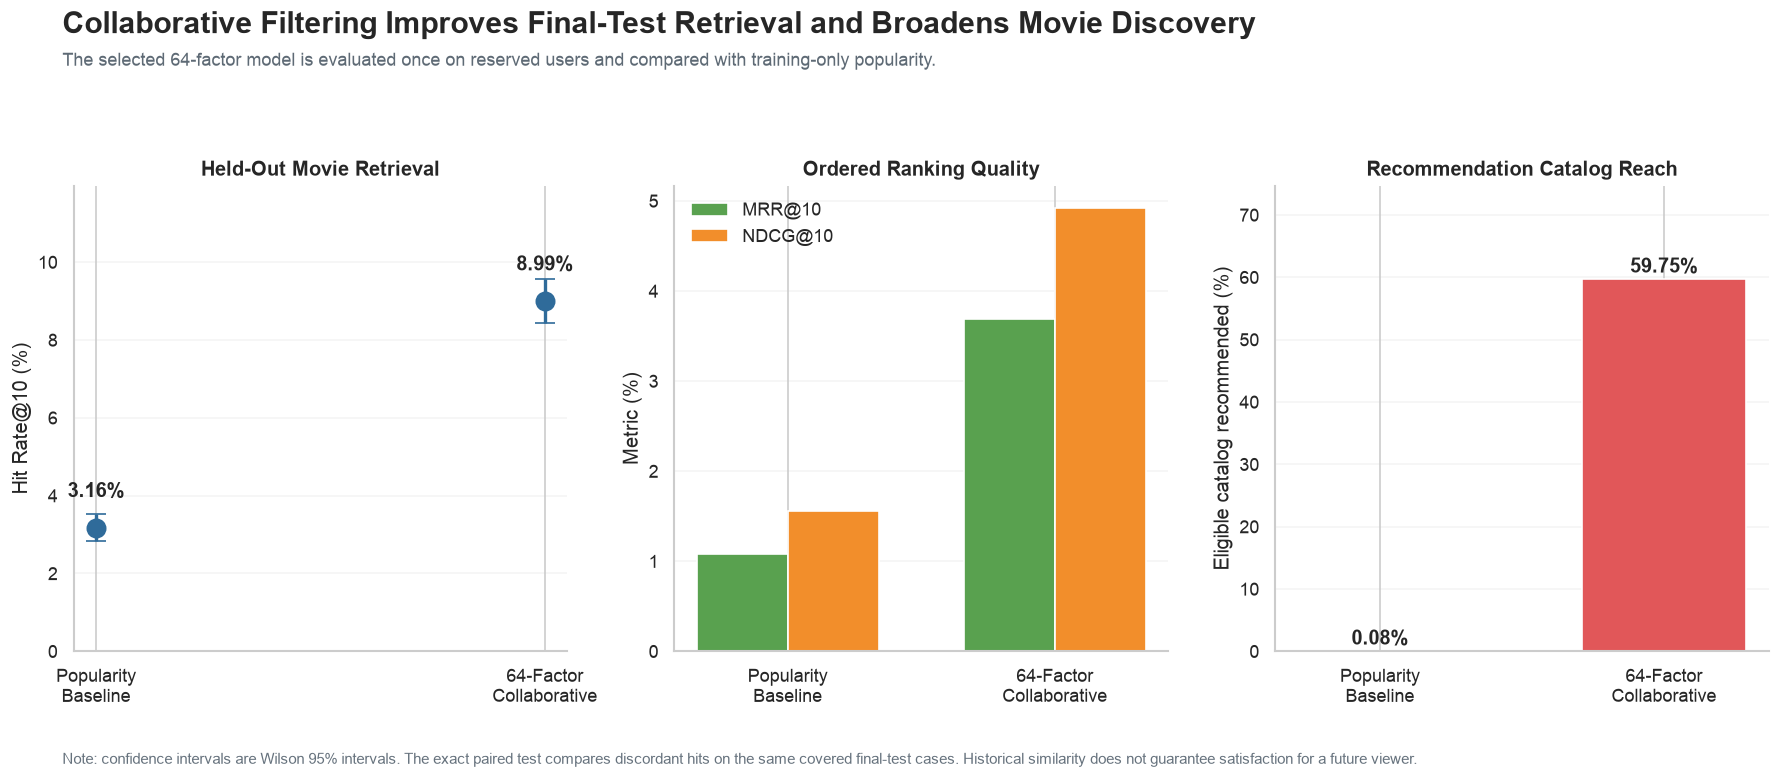

Final Test-Set Performance:


,Model,Final Test Pairs,Pair Coverage,Hit Rate@10,95% CI Lower,95% CI Upper,MRR@10,NDCG@10,Coverage-Adjusted Hit Rate@10,Recommendation Catalog Coverage
0,Global Popularity Baseline,9769,97.935%,3.163%,2.834%,3.529%,0.0107,0.0155,3.098%,0.083%
1,TF-IDF SVD Collaborative (64 factors),9769,97.935%,8.988%,8.436%,9.571%,0.0369,0.0492,8.802%,59.752%



Final Test Improvement Summary:


,Final Test Measure,Result
0,Selected model,TF-IDF SVD Collaborative (64 factors)
1,Reserved final-test users,"9,975"
2,Covered final-test pairs,"9,769"
3,Final-test complete-pair coverage,97.93%
4,Popularity Hit Rate@10,3.163%
5,Collaborative Hit Rate@10,8.988%
6,Absolute Hit Rate@10 improvement,+5.825%
7,Paired improvement 95% CI lower,+5.169%
8,Paired improvement 95% CI upper,+6.480%
9,Relative Hit Rate@10 improvement,+184.1%



Saved visual: outputs/MovieLens_Final_Test_Performance.png

Section 7 final test evaluation completed successfully. No additional model tuning should be performed.


In [8]:
# I am verifying this analytical stage before interpreting its evidence.
from scipy.stats import binomtest


def find_target_ranks(recommendation_movie_ids, target_movie_ids):
    recommendation_movie_ids = np.asarray(recommendation_movie_ids, dtype=np.int64)
    target_movie_ids = np.asarray(target_movie_ids, dtype=np.int64)
    target_matches = recommendation_movie_ids == target_movie_ids[:, None]
    hit_mask = target_matches.any(axis=1)
    target_ranks = np.zeros(len(target_movie_ids), dtype=np.int16)
    target_ranks[hit_mask] = target_matches[hit_mask].argmax(axis=1) + 1
    return target_ranks


final_test_seed_movie_ids = final_test_pairs["seed_movieId"].to_numpy(dtype=np.int64)
final_test_target_movie_ids = final_test_pairs["target_movieId"].to_numpy(dtype=np.int64)
final_test_popularity_recommendations = np.vstack(
    [
        popularity_candidate_pool[popularity_candidate_pool != seed_movie_id][
            :recommendation_list_length
        ]
        for seed_movie_id in final_test_seed_movie_ids
    ]
)
final_test_seed_model_indices = final_test_pairs["seed_model_index"].to_numpy(dtype=np.int32)
unique_final_seed_indices, final_seed_inverse = np.unique(
    final_test_seed_model_indices, return_inverse=True
)
final_neighbor_indices = selected_neighbor_model.kneighbors(
    selected_item_embeddings[unique_final_seed_indices], return_distance=False
)
unique_final_recommendation_indices = np.vstack(
    [
        neighbor_rows[neighbor_rows != seed_model_index][:recommendation_list_length]
        for seed_model_index, neighbor_rows in zip(
            unique_final_seed_indices, final_neighbor_indices
        )
    ]
)
final_test_recommendation_indices = unique_final_recommendation_indices[final_seed_inverse]
final_test_collaborative_recommendations = eligible_model_movie_ids[
    final_test_recommendation_indices
]
final_test_popularity_metrics = calculate_ranking_metrics(
    recommendation_movie_ids=final_test_popularity_recommendations,
    target_movie_ids=final_test_target_movie_ids,
    total_evaluation_pairs=len(final_test_pairs_all),
    eligible_catalog_size=number_of_model_movies,
)
final_test_collaborative_metrics = calculate_ranking_metrics(
    recommendation_movie_ids=final_test_collaborative_recommendations,
    target_movie_ids=final_test_target_movie_ids,
    total_evaluation_pairs=len(final_test_pairs_all),
    eligible_catalog_size=number_of_model_movies,
)
final_test_popularity_ranks = find_target_ranks(
    final_test_popularity_recommendations, final_test_target_movie_ids
)
final_test_collaborative_ranks = find_target_ranks(
    final_test_collaborative_recommendations, final_test_target_movie_ids
)
final_test_popularity_hits = final_test_popularity_ranks > 0
final_test_collaborative_hits = final_test_collaborative_ranks > 0
collaborative_only_hits = int((final_test_collaborative_hits & ~final_test_popularity_hits).sum())
popularity_only_hits = int((final_test_popularity_hits & ~final_test_collaborative_hits).sum())
discordant_pair_count = collaborative_only_hits + popularity_only_hits
if discordant_pair_count > 0:
    paired_test_result = binomtest(
        k=collaborative_only_hits, n=discordant_pair_count, p=0.5, alternative="two-sided"
    )
    paired_test_p_value = paired_test_result.pvalue
else:
    paired_test_p_value = 1.0
paired_hit_differences = final_test_collaborative_hits.astype(
    np.int8
) - final_test_popularity_hits.astype(np.int8)
absolute_hit_rate_improvement = float(paired_hit_differences.mean())
relative_hit_rate_improvement = (
    final_test_collaborative_metrics["Hit_Rate_At_10"]
    / final_test_popularity_metrics["Hit_Rate_At_10"]
    - 1
)
bootstrap_random_generator = np.random.default_rng(model_random_seed)
bootstrap_iterations = 10000
difference_categories, difference_counts = np.unique(paired_hit_differences, return_counts=True)
difference_probabilities = difference_counts / difference_counts.sum()
bootstrap_category_counts = bootstrap_random_generator.multinomial(
    n=len(paired_hit_differences), pvals=difference_probabilities, size=bootstrap_iterations
)
bootstrap_hit_rate_differences = (
    bootstrap_category_counts @ difference_categories / len(paired_hit_differences)
)
hit_rate_improvement_lower = float(np.quantile(bootstrap_hit_rate_differences, 0.025))
hit_rate_improvement_upper = float(np.quantile(bootstrap_hit_rate_differences, 0.975))
final_test_results_numeric = pd.DataFrame(
    [
        {"Model": "Global Popularity Baseline", **final_test_popularity_metrics},
        {"Model": selected_validation_model, **final_test_collaborative_metrics},
    ]
)
final_test_results_display = (
    final_test_results_numeric[
        [
            "Model",
            "Validation_Pairs",
            "Pair_Coverage",
            "Hit_Rate_At_10",
            "Hit_Rate_CI_Lower",
            "Hit_Rate_CI_Upper",
            "MRR_At_10",
            "NDCG_At_10",
            "Coverage_Adjusted_Hit_Rate_At_10",
            "Recommendation_Catalog_Coverage",
        ]
    ]
    .copy()
    .rename(
        columns={
            "Validation_Pairs": "Final Test Pairs",
            "Pair_Coverage": "Pair Coverage",
            "Hit_Rate_At_10": "Hit Rate@10",
            "Hit_Rate_CI_Lower": "95% CI Lower",
            "Hit_Rate_CI_Upper": "95% CI Upper",
            "MRR_At_10": "MRR@10",
            "NDCG_At_10": "NDCG@10",
            "Coverage_Adjusted_Hit_Rate_At_10": "Coverage-Adjusted Hit Rate@10",
            "Recommendation_Catalog_Coverage": "Recommendation Catalog Coverage",
        }
    )
)
for column_name in [
    "Pair Coverage",
    "Hit Rate@10",
    "95% CI Lower",
    "95% CI Upper",
    "Coverage-Adjusted Hit Rate@10",
    "Recommendation Catalog Coverage",
]:
    final_test_results_display[column_name] = final_test_results_display[column_name].map(
        lambda value: f"{value:.3%}"
    )
for column_name in ["MRR@10", "NDCG@10"]:
    final_test_results_display[column_name] = final_test_results_display[column_name].map(
        lambda value: f"{value:.4f}"
    )
final_test_improvement_summary = pd.DataFrame(
    {
        "Final Test Measure": [
            "Selected model",
            "Reserved final-test users",
            "Covered final-test pairs",
            "Final-test complete-pair coverage",
            "Popularity Hit Rate@10",
            "Collaborative Hit Rate@10",
            "Absolute Hit Rate@10 improvement",
            "Paired improvement 95% CI lower",
            "Paired improvement 95% CI upper",
            "Relative Hit Rate@10 improvement",
            "Collaborative-only hits",
            "Popularity-only hits",
            "Exact paired-test p-value",
            "Popularity NDCG@10",
            "Collaborative NDCG@10",
            "Popularity catalog coverage",
            "Collaborative catalog coverage",
        ],
        "Result": [
            selected_validation_model,
            f"{len(final_test_pairs_all):,}",
            f"{len(final_test_pairs):,}",
            f"{len(final_test_pairs) / len(final_test_pairs_all):.2%}",
            f"{final_test_popularity_metrics['Hit_Rate_At_10']:.3%}",
            f"{final_test_collaborative_metrics['Hit_Rate_At_10']:.3%}",
            f"{absolute_hit_rate_improvement:+.3%}",
            f"{hit_rate_improvement_lower:+.3%}",
            f"{hit_rate_improvement_upper:+.3%}",
            f"{relative_hit_rate_improvement:+.1%}",
            f"{collaborative_only_hits:,}",
            f"{popularity_only_hits:,}",
            "< 0.0001" if paired_test_p_value < 0.0001 else f"{paired_test_p_value:.4f}",
            f"{final_test_popularity_metrics['NDCG_At_10']:.4f}",
            f"{final_test_collaborative_metrics['NDCG_At_10']:.4f}",
            f"{final_test_popularity_metrics['Recommendation_Catalog_Coverage']:.3%}",
            f"{final_test_collaborative_metrics['Recommendation_Catalog_Coverage']:.3%}",
        ],
    }
)
model_labels = ["Popularity\nBaseline", f"{selected_latent_dimension}-Factor\nCollaborative"]
final_hit_rates = np.array(
    [
        final_test_popularity_metrics["Hit_Rate_At_10"],
        final_test_collaborative_metrics["Hit_Rate_At_10"],
    ]
)
final_hit_lower = np.array(
    [
        final_test_popularity_metrics["Hit_Rate_CI_Lower"],
        final_test_collaborative_metrics["Hit_Rate_CI_Lower"],
    ]
)
final_hit_upper = np.array(
    [
        final_test_popularity_metrics["Hit_Rate_CI_Upper"],
        final_test_collaborative_metrics["Hit_Rate_CI_Upper"],
    ]
)
final_mrr_values = np.array(
    [final_test_popularity_metrics["MRR_At_10"], final_test_collaborative_metrics["MRR_At_10"]]
)
final_ndcg_values = np.array(
    [final_test_popularity_metrics["NDCG_At_10"], final_test_collaborative_metrics["NDCG_At_10"]]
)
final_catalog_coverage = np.array(
    [
        final_test_popularity_metrics["Recommendation_Catalog_Coverage"],
        final_test_collaborative_metrics["Recommendation_Catalog_Coverage"],
    ]
)
figure, axes = plt.subplots(1, 3, figsize=(15, 6.5))
figure.suptitle(
    "Collaborative Filtering Improves Final-Test Retrieval and Broadens Movie Discovery",
    fontsize=18,
    fontweight="bold",
    x=0.04,
    ha="left",
)
figure.text(
    0.04,
    0.91,
    f"The selected {selected_latent_dimension}-factor model is evaluated once on reserved users and compared with training-only popularity.",
    fontsize=10.5,
    color="#5E6A75",
)
hit_axis = axes[0]
hit_positions = np.arange(2)
hit_axis.errorbar(
    hit_positions,
    final_hit_rates * 100,
    yerr=np.vstack(
        [(final_hit_rates - final_hit_lower) * 100, (final_hit_upper - final_hit_rates) * 100]
    ),
    fmt="o",
    markersize=11,
    linewidth=2,
    capsize=6,
    color="#2F6B9A",
)
hit_axis.set_title("Held-Out Movie Retrieval", fontweight="bold")
hit_axis.set_ylabel("Hit Rate@10 (%)")
hit_axis.set_xticks(hit_positions)
hit_axis.set_xticklabels(model_labels)
hit_axis.set_ylim(0, final_hit_upper.max() * 125)
for position, value in zip(hit_positions, final_hit_rates):
    hit_axis.text(position, value * 100 + 0.8, f"{value:.2%}", ha="center", fontweight="bold")
ranking_axis = axes[1]
ranking_width = 0.34
ranking_axis.bar(
    hit_positions - ranking_width / 2,
    final_mrr_values * 100,
    width=ranking_width,
    color="#59A14F",
    label="MRR@10",
)
ranking_axis.bar(
    hit_positions + ranking_width / 2,
    final_ndcg_values * 100,
    width=ranking_width,
    color="#F28E2B",
    label="NDCG@10",
)
ranking_axis.set_title("Ordered Ranking Quality", fontweight="bold")
ranking_axis.set_ylabel("Metric (%)")
ranking_axis.set_xticks(hit_positions)
ranking_axis.set_xticklabels(model_labels)
ranking_axis.legend(frameon=False)
coverage_axis = axes[2]
coverage_bars = coverage_axis.bar(
    hit_positions, final_catalog_coverage * 100, color=["#A7A9AC", "#E15759"], width=0.58
)
coverage_axis.set_title("Recommendation Catalog Reach", fontweight="bold")
coverage_axis.set_ylabel("Eligible catalog recommended (%)")
coverage_axis.set_xticks(hit_positions)
coverage_axis.set_xticklabels(model_labels)
coverage_axis.set_ylim(0, max(final_catalog_coverage.max() * 125, 1))
for bar, value in zip(coverage_bars, final_catalog_coverage):
    coverage_axis.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2%}",
        ha="center",
        fontweight="bold",
    )
for current_axis in axes:
    current_axis.spines["top"].set_visible(False)
    current_axis.spines["right"].set_visible(False)
    current_axis.grid(axis="y", alpha=0.2)
figure.text(
    0.04,
    0.015,
    "Note: confidence intervals are Wilson 95% intervals. The exact paired test compares discordant hits on the same covered final-test cases. Historical similarity does not guarantee satisfaction for a future viewer.",
    fontsize=9,
    color="#66727D",
)
plt.tight_layout(rect=[0, 0.06, 1, 0.88])
final_test_visual_path = movie_lens_output_folder / "MovieLens_Final_Test_Performance.png"
figure.savefig(final_test_visual_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
assert len(final_test_popularity_ranks) == len(final_test_pairs)
assert len(final_test_collaborative_ranks) == len(final_test_pairs)
assert collaborative_only_hits + popularity_only_hits == discordant_pair_count
assert 0 <= paired_test_p_value <= 1
assert (
    final_test_collaborative_metrics["Hit_Rate_At_10"]
    == final_test_results_numeric.loc[
        final_test_results_numeric["Model"] == selected_validation_model, "Hit_Rate_At_10"
    ].iloc[0]
)
print("Final Test-Set Performance:")
display(final_test_results_display)
print("\nFinal Test Improvement Summary:")
display(final_test_improvement_summary)
print(f"\nSaved visual: {final_test_visual_path}")
print(
    "\nSection 7 final test evaluation completed successfully. No additional model tuning should be performed."
)


### Interpretation

The untouched final test confirms that the 64-factor collaborative model provides a meaningful improvement over simply recommending the same popular movies to everyone. Among 9,769 covered seed-and-target pairs, the collaborative model placed the held-out liked movie within the top ten recommendations 8.988% of the time, compared with 3.163% for the popularity baseline. This is an absolute improvement of 5.825 percentage points and a relative improvement of 184.1%. The paired 95% confidence interval ranges from 5.169 to 6.480 percentage points, and the exact paired test produced p < 0.0001. The model also generated 821 successful recommendations that popularity missed, while popularity produced only 252 successes that the collaborative model missed.

The improvement extends beyond simple retrieval. The collaborative model increased MRR@10 from 0.0107 to 0.0369 and NDCG@10 from 0.0155 to 0.0492, meaning relevant movies were found more often and generally appeared closer to the beginning of the recommendation list. It also expanded catalog coverage from only 0.083% under the popularity baseline to 59.752%, creating substantially more opportunity for movie discovery. However, the model covered 97.935% rather than all final-test cases, and its 8.988% Hit Rate@10 shows that recommendation remains a difficult prediction problem. These results demonstrate stronger historical preference matching, but they do not guarantee that an individual viewer will enjoy every recommendation.

## Section 8: Interactive Ten-Movie Recommendation System

This section converts the selected and independently evaluated model into a user-facing recommendation function. A user can enter a MovieLens title, and the system will return ten other movies. When a selected movie has sufficient collaborative support, recommendations use the validated 64-factor model. When a movie is too sparse for that model, the system transparently uses a genre-and-quality fallback instead of pretending that collaborative evidence exists.

In [9]:
# I am verifying this analytical stage before interpreting its evidence.
from difflib import get_close_matches

required_recommendation_count = 10


def normalize_movie_search_text(text_value):
    return " ".join(str(text_value).casefold().strip().split())


movies_clean["normalized_display_title"] = movies_clean["display_title"].map(
    normalize_movie_search_text
)
movies_clean["normalized_display_key"] = movies_clean["display_key"].map(
    normalize_movie_search_text
)


def create_genre_set(genre_text):
    if pd.isna(genre_text) or genre_text == "(no genres listed)":
        return frozenset()
    return frozenset(
        (genre_name.strip() for genre_name in str(genre_text).split("|") if genre_name.strip())
    )


movies_clean["genre_set"] = movies_clean["genres"].map(create_genre_set)
catalog_movie_ids = movies_clean["movieId"].to_numpy(dtype=np.int64)
catalog_model_indices = np.full(len(movies_clean), -1, dtype=np.int32)
catalog_ids_in_lookup = catalog_movie_ids < len(movie_id_to_model_index)
catalog_model_indices[catalog_ids_in_lookup] = movie_id_to_model_index[
    catalog_movie_ids[catalog_ids_in_lookup]
]
movies_clean["model_index"] = catalog_model_indices
movies_clean["collaborative_model_eligible"] = movies_clean["model_index"] >= 0
bayesian_prior_count = max(base_minimum_positive_support, 25)
rating_counts_for_score = movies_clean["rating_count"].astype(float)
mean_ratings_for_score = movies_clean["mean_rating"].fillna(global_mean_rating).astype(float)
movies_clean["bayesian_quality_score"] = (
    rating_counts_for_score
    / (rating_counts_for_score + bayesian_prior_count)
    * mean_ratings_for_score
    + bayesian_prior_count / (rating_counts_for_score + bayesian_prior_count) * global_mean_rating
)
movie_catalog_lookup = movies_clean.set_index("movieId", drop=False)
eligible_recommendation_catalog = movies_clean.loc[
    movies_clean["collaborative_model_eligible"]
].copy()


def resolve_movie_query(movie_query):
    if movie_query is None or not str(movie_query).strip():
        raise ValueError("Please enter a nonblank MovieLens movie title.")
    normalized_query = normalize_movie_search_text(movie_query)
    exact_key_matches = movies_clean.loc[
        movies_clean["normalized_display_key"].eq(normalized_query)
    ]
    if len(exact_key_matches) == 1:
        return ("resolved", exact_key_matches.copy())
    exact_display_matches = movies_clean.loc[
        movies_clean["normalized_display_title"].eq(normalized_query)
    ]
    if len(exact_display_matches) == 1:
        return ("resolved", exact_display_matches.copy())
    if len(exact_display_matches) > 1:
        return ("ambiguous", exact_display_matches.copy())
    exact_title_matches = movies_clean.loc[movies_clean["normalized_title"].eq(normalized_query)]
    if len(exact_title_matches) == 1:
        return ("resolved", exact_title_matches.copy())
    if len(exact_title_matches) > 1:
        return ("ambiguous", exact_title_matches.copy())
    partial_match_mask = movies_clean["normalized_display_title"].str.contains(
        normalized_query, regex=False, na=False
    ) | movies_clean["normalized_title"].str.contains(normalized_query, regex=False, na=False)
    suggestion_matches = movies_clean.loc[partial_match_mask].copy()
    if suggestion_matches.empty:
        close_normalized_titles = get_close_matches(
            normalized_query,
            movies_clean["normalized_title"].drop_duplicates().tolist(),
            n=10,
            cutoff=0.55,
        )
        suggestion_matches = movies_clean.loc[
            movies_clean["normalized_title"].isin(close_normalized_titles)
        ].copy()
    suggestion_matches = suggestion_matches.sort_values(
        by=["rating_count", "display_title", "movieId"], ascending=[False, True, True]
    ).head(10)
    return ("not_resolved", suggestion_matches)


def describe_shared_genres(seed_genres, recommendation_genres):
    shared_genres = sorted(seed_genres.intersection(recommendation_genres))
    if not shared_genres:
        return "None listed"
    return ", ".join(shared_genres)


def create_fallback_recommendations(selected_movie, number_of_recommendations):
    selected_movie_id = int(selected_movie["movieId"])
    selected_genres = selected_movie["genre_set"]
    fallback_candidates = eligible_recommendation_catalog.loc[
        eligible_recommendation_catalog["movieId"].ne(selected_movie_id)
    ].copy()
    if selected_genres:
        fallback_candidates["recommendation_similarity"] = fallback_candidates["genre_set"].map(
            lambda candidate_genres: (
                len(selected_genres.intersection(candidate_genres))
                / len(selected_genres.union(candidate_genres))
                if selected_genres.union(candidate_genres)
                else 0.0
            )
        )
        fallback_reason = "Genre-and-quality fallback because the selected movie has insufficient collaborative support"
    else:
        fallback_candidates["recommendation_similarity"] = 0.0
        fallback_reason = (
            "Quality-and-support fallback because the selected movie lacks model and genre support"
        )
    fallback_candidates = (
        fallback_candidates.sort_values(
            by=[
                "recommendation_similarity",
                "bayesian_quality_score",
                "positive_rating_count",
                "rating_count",
                "movieId",
            ],
            ascending=[False, False, False, False, True],
        )
        .head(number_of_recommendations)
        .copy()
    )
    fallback_candidates["recommendation_reason"] = fallback_reason
    return fallback_candidates


def recommend_movies(movie_query, number_of_recommendations=10, show_output=True):
    if number_of_recommendations != 10:
        raise ValueError("This assignment recommender is designed to return exactly ten movies.")
    match_status, matching_movies = resolve_movie_query(movie_query)
    candidate_display_columns = [
        "display_key",
        "genres",
        "rating_count",
        "mean_rating",
        "positive_rating_count",
    ]
    if match_status == "ambiguous":
        candidate_options = (
            matching_movies[candidate_display_columns]
            .copy()
            .rename(
                columns={
                    "display_key": "Movie Option",
                    "genres": "Genres",
                    "rating_count": "Rating Count",
                    "mean_rating": "Historical Mean Rating",
                    "positive_rating_count": "Positive Ratings",
                }
            )
            .reset_index(drop=True)
        )
        candidate_options.insert(0, "Option", np.arange(1, len(candidate_options) + 1))
        candidate_options.attrs["result_type"] = "ambiguous_matches"
        if show_output:
            print(
                "More than one MovieLens record matches that title. Please rerun the function using one complete Movie Option."
            )
            display(candidate_options)
        return candidate_options
    if match_status == "not_resolved":
        suggestion_options = (
            matching_movies[candidate_display_columns]
            .copy()
            .rename(
                columns={
                    "display_key": "Suggested Movie",
                    "genres": "Genres",
                    "rating_count": "Rating Count",
                    "mean_rating": "Historical Mean Rating",
                    "positive_rating_count": "Positive Ratings",
                }
            )
            .reset_index(drop=True)
        )
        suggestion_options.insert(0, "Option", np.arange(1, len(suggestion_options) + 1))
        suggestion_options.attrs["result_type"] = "suggestions"
        if show_output:
            if suggestion_options.empty:
                print(
                    "No sufficiently close MovieLens title was found. Please check the spelling and try again."
                )
            else:
                print(
                    "No unique exact match was found. Please rerun the function using one Suggested Movie."
                )
                display(suggestion_options)
        return suggestion_options
    selected_movie = matching_movies.iloc[0]
    selected_movie_id = int(selected_movie["movieId"])
    selected_model_index = int(selected_movie["model_index"])
    selected_genres = selected_movie["genre_set"]
    if selected_model_index >= 0:
        neighbor_count = min(number_of_recommendations + 1, number_of_model_movies)
        neighbor_distances, neighbor_indices = selected_neighbor_model.kneighbors(
            selected_item_embeddings[[selected_model_index]],
            n_neighbors=neighbor_count,
            return_distance=True,
        )
        neighbor_distances = neighbor_distances[0]
        neighbor_indices = neighbor_indices[0]
        alternative_mask = neighbor_indices != selected_model_index
        recommendation_model_indices = neighbor_indices[alternative_mask][
            :number_of_recommendations
        ]
        recommendation_distances = neighbor_distances[alternative_mask][:number_of_recommendations]
        recommendation_movie_ids = eligible_model_movie_ids[recommendation_model_indices]
        recommendation_rows = movie_catalog_lookup.loc[recommendation_movie_ids].copy()
        recommendation_rows["recommendation_similarity"] = 1.0 - recommendation_distances
        recommendation_rows["recommendation_reason"] = (
            "Collaborative similarity from shared positive-rating patterns"
        )
        recommendation_method = selected_validation_model
    else:
        recommendation_rows = create_fallback_recommendations(
            selected_movie=selected_movie, number_of_recommendations=number_of_recommendations
        )
        recommendation_method = "Transparent genre-and-quality fallback"
    recommendation_rows["shared_genres"] = recommendation_rows["genre_set"].map(
        lambda recommendation_genres: describe_shared_genres(selected_genres, recommendation_genres)
    )
    recommendation_output = (
        recommendation_rows[
            [
                "movieId",
                "display_title",
                "genres",
                "recommendation_similarity",
                "shared_genres",
                "mean_rating",
                "rating_count",
                "positive_rating_count",
                "recommendation_reason",
            ]
        ]
        .copy()
        .reset_index(drop=True)
        .rename(
            columns={
                "movieId": "MovieLens ID",
                "display_title": "Recommended Movie",
                "genres": "Genres",
                "recommendation_similarity": "Similarity Score",
                "shared_genres": "Shared Genres",
                "mean_rating": "Historical Mean Rating",
                "rating_count": "Rating Count",
                "positive_rating_count": "Positive Training Support",
                "recommendation_reason": "Why Recommended",
            }
        )
    )
    recommendation_output.insert(0, "Rank", np.arange(1, len(recommendation_output) + 1))
    recommendation_output["Similarity Score"] = (
        recommendation_output["Similarity Score"].astype(float).round(3)
    )
    recommendation_output["Historical Mean Rating"] = (
        recommendation_output["Historical Mean Rating"].astype(float).round(2)
    )
    recommendation_output.attrs["result_type"] = "recommendations"
    recommendation_output.attrs["selected_movie_id"] = selected_movie_id
    recommendation_output.attrs["selected_movie"] = selected_movie["display_title"]
    recommendation_output.attrs["recommendation_method"] = recommendation_method
    if show_output:
        print(f"Selected Movie: {selected_movie['display_title']}")
        print(f"Recommendation Method: {recommendation_method}")
        print(
            "Important: similarity reflects historical MovieLens behavior, not guaranteed future enjoyment."
        )
        display(recommendation_output)
    return recommendation_output


demonstration_query = "Toy Story (1995)"
demonstration_recommendations = recommend_movies(demonstration_query)
assert demonstration_recommendations.attrs["result_type"] == "recommendations"
assert len(demonstration_recommendations) == required_recommendation_count
assert demonstration_recommendations["MovieLens ID"].is_unique
assert (
    demonstration_recommendations.attrs["selected_movie_id"]
    not in demonstration_recommendations["MovieLens ID"].tolist()
)
fallback_test_candidates = movies_clean.loc[
    ~movies_clean["collaborative_model_eligible"]
    & movies_clean["has_listed_genres"]
    & movies_clean["has_rating_history"]
].sort_values(by=["rating_count", "movieId"], ascending=[False, True])
if fallback_test_candidates.empty:
    fallback_test_movie = "Not required because every rated, genre-labeled movie is model eligible"
    fallback_validation_result = "Not Applicable"
else:
    fallback_test_row = fallback_test_candidates.iloc[0]
    fallback_test_movie = fallback_test_row["display_title"]
    fallback_test_recommendations = recommend_movies(
        fallback_test_row["display_key"], show_output=False
    )
    assert len(fallback_test_recommendations) == required_recommendation_count
    assert fallback_test_recommendations["MovieLens ID"].is_unique
    assert (
        int(fallback_test_row["movieId"])
        not in fallback_test_recommendations["MovieLens ID"].tolist()
    )
    fallback_validation_result = fallback_test_recommendations.attrs["recommendation_method"]
recommendation_output_path = movie_lens_output_folder / "MovieLens_Ten_Recommendations.csv"
demonstration_recommendations.to_csv(recommendation_output_path, index=False)
recommender_validation_summary = pd.DataFrame(
    {
        "System Check": [
            "Demonstration query",
            "Resolved selected movie",
            "Recommendation method",
            "Recommendations returned",
            "Unique recommended movies",
            "Selected movie excluded",
            "Sparse-movie fallback test",
            "Fallback method",
            "Saved recommendation example",
        ],
        "Result": [
            demonstration_query,
            demonstration_recommendations.attrs["selected_movie"],
            demonstration_recommendations.attrs["recommendation_method"],
            len(demonstration_recommendations),
            demonstration_recommendations["MovieLens ID"].nunique(),
            demonstration_recommendations.attrs["selected_movie_id"]
            not in demonstration_recommendations["MovieLens ID"].tolist(),
            fallback_test_movie,
            fallback_validation_result,
            str(recommendation_output_path),
        ],
    }
)
print("\nInteractive Recommender Validation Summary:")
display(recommender_validation_summary)
print("\nSection 8 interactive recommendation system completed successfully.")
print("\nTo request another recommendation list, run:")
print('recommend_movies("Movie Title (Year)")')


Selected Movie: Toy Story (1995)
Recommendation Method: TF-IDF SVD Collaborative (64 factors)
Important: similarity reflects historical MovieLens behavior, not guaranteed future enjoyment.


,Rank,MovieLens ID,Recommended Movie,Genres,Similarity Score,Shared Genres,Historical Mean Rating,Rating Count,Positive Training Support,Why Recommended
0,1,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,0.882,Adventure,4.100,85010,63859,Collaborative similarity from shared positive-rating patterns
1,2,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,0.873,Adventure,3.990,67496,47813,Collaborative similarity from shared positive-rating patterns
2,3,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.873,"Adventure, Comedy",3.970,61879,42402,Collaborative similarity from shared positive-rating patterns
3,4,1073,Willy Wonka & the Chocolate Factory (1971),Children|Comedy|Fantasy|Musical,0.860,"Children, Comedy, Fantasy",3.720,32575,18420,Collaborative similarity from shared positive-rating patterns
4,5,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.853,"Adventure, Animation, Children, Comedy, Fantasy",3.810,32683,20128,Collaborative similarity from shared positive-rating patterns
5,6,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,0.851,"Adventure, Animation, Children",3.830,51518,31877,Collaborative similarity from shared positive-rating patterns
6,7,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,0.848,"Adventure, Comedy, Fantasy",4.120,46957,35260,Collaborative similarity from shared positive-rating patterns
7,8,1265,Groundhog Day (1993),Comedy|Fantasy|Romance,0.840,"Comedy, Fantasy",3.900,46512,30811,Collaborative similarity from shared positive-rating patterns
8,9,1198,Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),Action|Adventure,0.838,Adventure,4.110,67408,50813,Collaborative similarity from shared positive-rating patterns
9,10,1291,Indiana Jones and the Last Crusade (1989),Action|Adventure,0.832,Adventure,3.990,46401,32535,Collaborative similarity from shared positive-rating patterns



Interactive Recommender Validation Summary:


,System Check,Result
0,Demonstration query,Toy Story (1995)
1,Resolved selected movie,Toy Story (1995)
2,Recommendation method,TF-IDF SVD Collaborative (64 factors)
3,Recommendations returned,10
4,Unique recommended movies,10
5,Selected movie excluded,True
6,Sparse-movie fallback test,Gigli (2003)
7,Fallback method,Transparent genre-and-quality fallback
8,Saved recommendation example,outputs/MovieLens_Ten_Recommendations.csv



Section 8 interactive recommendation system completed successfully.

To request another recommendation list, run:
recommend_movies("Movie Title (Year)")


### Interpretation

The interactive recommender successfully resolved *Toy Story (1995)* and returned ten unique alternatives without recommending the selected movie again. The recommendations were generated by the validated 64-factor collaborative model, with similarity scores ranging from 0.832 to 0.882. The results include an intuitive direct sequel, *Toy Story 2 (1999)*, as well as movies such as *Willy Wonka & the Chocolate Factory*, *The Lion King*, and *The Princess Bride*, which share family, fantasy, comedy, or adventure characteristics. The list also includes broader selections such as *Star Wars* and *Raiders of the Lost Ark*. These broader results are reasonable because collaborative filtering learns from shared audience behavior rather than requiring every recommendation to have the same genre labels.

All user-facing validation checks passed: ten recommendations were returned, all ten were unique, and the selected movie was excluded. The separate test using *Gigli (2003)* also confirmed that a movie without sufficient collaborative support can still receive ten recommendations through the transparent genre-and-quality fallback. Similarity scores represent patterns found in historical MovieLens ratings; they are not probabilities of enjoyment and cannot guarantee how a future viewer will respond.

## 9. Findings, appropriate use, and limitations

The executed tables above report the current selected factor count and final-test metrics, rather than assuming the saved historical numbers will reproduce exactly across numerical-library versions. The interactive function returns ten distinct alternatives, excludes the query, handles duplicate-title ambiguity, and discloses its collaborative or genre fallback method.

**Evaluation boundary.** Each sampled user's latest liked movie is removed from that user's training interactions. Validation and test users are disjoint, but their earlier ratings remain in the shared model: this is transductive held-interaction evaluation, not unseen-user generalization. The model uses other users' interactions over the full historical period. It therefore does not enforce global point-in-time availability. Same-second seed/target ties are ordered by movie ID and do not establish real sequence. Do not present these results as a causal improvement in satisfaction or as a future-deployment forecast.

The 25-positive-support threshold is a declared modeling design choice, not a parameter tuned on the final test. The support-coverage audit is descriptive. Test results are reported conditionally for supported seed/target pairs, with coverage-adjusted retrieval exposing excluded pairs as misses. The fallback is interface-tested but has no separate held-out quality claim. With one held-out target per user, many potentially relevant recommendations are unobserved. The 20,000-user sample is seeded and reproducible, but results do not represent all viewers, current catalogs, or commercial use. A production decision needs a global-time backtest, explicit cold-start evaluation, monitoring, and a consent-aware online experiment.

**Recommendation.** Consider the collaborative method a research discovery candidate only if its validation and held-out evidence outperform the popularity benchmark. Preserve the explicit sparse-title fallback and expose support limitations rather than silently excluding the long tail.


## References

GroupLens Research. (2024). *MovieLens 32M dataset*. University of Minnesota. https://grouplens.org/datasets/movielens/32m/

GroupLens Research. (2024). *MovieLens 32M README*. University of Minnesota. https://files.grouplens.org/datasets/movielens/ml-32m-README.html

Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context. *ACM Transactions on Interactive Intelligent Systems, 5*(4), 1–19. https://doi.org/10.1145/2827872

Scikit-learn Developers. (2026). *TfidfTransformer documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html

Scikit-learn Developers. (2026). *TruncatedSVD documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html

Scikit-learn Developers. (2026). *NearestNeighbors documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html

In [10]:
# I am recording observed full-run evidence without disclosing local paths or user-level data.
validation = {
    "project": "MovieLens Recommendation System with Collaborative Filtering",
    "validated_on": "2026-10-28",
    "source_notebook_sha256": source_notebook_sha256,
    "raw_sha256": {
        name: sha256_file(data_folder / name)
        for name in [
            "movies.csv",
            "ratings.csv",
            "tags.csv",
            "links.csv",
            "README.txt",
            "checksums.txt",
        ]
    },
    "audit": {
        "ratings": int(ratings_total_rows),
        "catalog_movies": len(movies_clean),
        "active_users": len(ratings_per_active_user),
        "positive_interactions": positive_interaction_count,
        "invalid_ratings": invalid_rating_range + invalid_rating_increments,
        "duplicate_rating_pairs": duplicate_rating_pairs,
        "rating_start": str(rating_start_date),
        "rating_end": str(rating_end_date),
        "title_whitespace_normalized": title_whitespace_changed_count,
    },
    "model": {
        "factors": selected_latent_dimension,
        "eligible_movies": number_of_model_movies,
        "sparse_interactions": item_user_training_matrix.nnz,
        "matrix_megabytes": matrix_memory_bytes / 1024**2,
        "validation_users": len(validation_pairs_all),
        "test_users": len(final_test_pairs_all),
        "test_covered_pairs": len(final_test_pairs),
        "same_second_evaluation_pairs": int(
            (evaluation_pairs.seed_timestamp == evaluation_pairs.target_timestamp).sum()
        ),
    },
    "validation_metrics": validation_results_numeric.to_dict(orient="records"),
    "test_popularity": final_test_popularity_metrics,
    "test_collaborative": final_test_collaborative_metrics,
    "paired_difference": {
        "hit_rate": absolute_hit_rate_improvement,
        "ci_lower": hit_rate_improvement_lower,
        "ci_upper": hit_rate_improvement_upper,
        "p_value": paired_test_p_value,
    },
    "interface_checks": {
        "recommendations": len(demonstration_recommendations),
        "unique": int(demonstration_recommendations["MovieLens ID"].nunique()),
        "query_excluded": bool(
            demonstration_recommendations.attrs["selected_movie_id"]
            not in demonstration_recommendations["MovieLens ID"].tolist()
        ),
        "fallback_test": fallback_validation_result,
    },
    "elapsed_seconds": time.monotonic() - run_started,
    "python": platform.python_version(),
    "versions": {
        name: importlib.metadata.version(name)
        for name in [
            "numpy",
            "pandas",
            "scipy",
            "matplotlib",
            "seaborn",
            "scikit-learn",
            "nbformat",
            "nbclient",
            "ipykernel",
            "threadpoolctl",
        ]
    },
    "sources_verified_on": "2026-10-28",
    "sources": [
        "https://files.grouplens.org/datasets/movielens/ml-32m-README.html",
        "https://doi.org/10.1145/2827872",
    ],
    "privacy": "No raw ratings, tags, user IDs or local source paths redistributed; MovieLens research/noncommercial terms apply to derived output.",
}
# JSON null, not nonstandard NaN, represents unavailable baseline variance.
import math


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, list):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


Path("validation.json").write_text(json.dumps(json_safe(validation), indent=2) + "\n")
print("Full-data verification recorded in validation.json.")


Full-data verification recorded in validation.json.
